# HiRID — Predizione del deterioramento clinico con NEWS-2 e Delta-NEWS
### Tesi Triennale in Ingegneria Biomedica — database di riferimento

**Tesi:** *Progettazione di un modulo di interoperabilità per la sorveglianza automatizzata in terapia sub-intensiva*

**Domanda di ricerca:**
> È possibile progettare un modello di sorveglianza automatizzata che, a partire dai parametri
> vitali di routine sintetizzati nel NEWS-2 e nella sua evoluzione nel tempo (Delta-NEWS),
> predica il deterioramento clinico entro 24 ore, e che sia interoperabile, cioè applicabile
> con la stessa metodologia a basi dati cliniche eterogenee (MIMIC-IV, eICU-CRD, HiRID)?

**Interoperabilità:** i tre database usano schemi, codifiche e unità di misura diverse
(itemid in MIMIC-IV, nomi testuali in eICU-CRD, variableid in HiRID; temperature in °F e °C;
GCS verbale o totale). Ogni notebook traduce la propria sorgente nello stesso insieme comune di
20 variabili, con lo stesso endpoint e gli stessi modelli: è questo strato di armonizzazione che
rende il modello trasferibile da una base dati all'altra.

**Terapia sub-intensiva:** il modello è **pensato per** la sorveglianza automatizzata in terapia
sub-intensiva: il NEWS-2, su cui si basa, è nato proprio per il monitoraggio dei pazienti fuori dalla
terapia intensiva. Poiché non esistono database pubblici di terapia sub-intensiva con parametri vitali
ad alta frequenza, è stato **sviluppato e validato su** dati di terapia intensiva, il setting più vicino
disponibile. La validazione su dati di terapia sub-intensiva è lo sviluppo futuro naturale del lavoro.

---

HiRID è il **database di riferimento** della tesi: è usato per intero (nessun campione), ha misure ogni
~2 minuti ed è un solo ospedale con documentazione uniforme. MIMIC-IV è il confronto principale, eICU-CRD il
confronto secondario: i tre notebook applicano la stessa pipeline.

**Fase 1 — dati**
1. Estrazione dei parametri vitali dalla observation table
2. Pulizia dei valori clinicamente impossibili (outlier)
3. Ricampionamento a griglia fissa di 10 minuti
4. Gestione dei valori mancanti (flag e imputazione)
5. Calcolo del punteggio NEWS-2 e del Delta-NEWS (istantaneo e a 6 ore)
6. Costruzione dell'endpoint composito di deterioramento a 24 ore (morte, inizio di vasopressori, intubazione), contando solo l'**insorgenza** degli eventi
7. Divisione in training (60%), validation (20%), test (20%) per paziente, salvata in tre file CSV

**Fase 2 — modelli e valutazione**
8. Addestramento di Logistic Regression, Random Forest e XGBoost
9. Scelta del modello sulla validazione (punteggio composito) e confronto con il NEWS-2 usato da solo
10. Interpretabilità con SHAP
11. Intervallo di confidenza al 95% con bootstrap per paziente
12. Ricalibrazione isotonica e Decision Curve Analysis
13. Tempo di anticipo degli allarmi, con falsi allarmi e confronto con le soglie del NEWS-2
14. Consensus dei tre modelli (ensemble) e confronto con il modello scelto

---

### Differenze strutturali rispetto a MIMIC-IV / eICU-CRD

| Aspetto | MIMIC-IV | eICU-CRD | HiRID |
|---|---|---|---|
| Unità di analisi | subject_id | patientunitstayid | patientid |
| Tempo | charttime | observationoffset (min) | datetime |
| Formato misurazioni | chartevents, long (itemid) | vitalPeriodic wide + nurseCharting long | observation table, long (variableid) |
| GCS → AVPU | verbale 1-5, soglia < 5 | totale 3-15, soglia < 14 | tre sotto-punteggi separati, sommati a un totale 3-15, stessa soglia < 14 di eICU |
| Vasopressori | inputevents (item ID) | infusionDrug (keyword) | pharma table (pharmaid) |
| Intubazione | procedureevents (item ID, evento discreto) | treatment (keyword, evento discreto) | non esiste un evento discreto: derivata come prima transizione a un codice di via aerea invasiva (intubato/tracheotomizzato) |
| Morte | hospital_expire_flag + deathtime durante la degenza ICU (timestamp preciso) | unitdischargestatus = Expired, orario unitdischargeoffset (solo decessi in ICU) | discharge_status della general table — **attenzione**: manca un timestamp preciso, si usa come proxy l'ultima misurazione osservata (limite discusso nella Parte 8) |

Tutta la configurazione della Parte 0 è ormai confermata dalla `hirid_variable_reference.csv`
e dalla `ordinal_vars_ref.csv` reali. L'unico punto ancora da tenere d'occhio è il proxy
sul timing della morte (Parte 8), un limite strutturale di HiRID e non una configurazione mancante.

## PARTE 0 — Configurazione
- Importiamo pandas per la manipolazione dei dati, numpy per i calcoli numerici
- Path e os per gestire cartelle e percorsi file in modo compatibile Windows/Mac
- A differenza di MIMIC-IV ed eICU-CRD, qui i parametri non hanno un nome diretto nei dati:
  HiRID identifica ogni misurazione con un codice numerico (`variableid`), quindi la
  configurazione è soprattutto una mappa "nome del parametro → codice/i HiRID"
- I valori vitali hanno più di un ID quando la reference table elenca più fonti/dispositivi
  per lo stesso parametro clinico (es. tre ID diversi tutti etichettati "Respiratory rate")

In [1]:
import pandas as pd            # libreria principale per manipolare tabelle di dati
import numpy as np             # calcoli numerici e gestione dei valori mancanti (NaN)
from pathlib import Path       # gestisce i percorsi dei file in modo indipendente dal sistema operativo
import os                      # crea le cartelle di output se non esistono già

BASE_PATH = Path("hirid-a-high-time-resolution-icu-dataset-1.1.1")  # se sposti la cartella, aggiorna solo questa riga
CARTELLA_OUTPUT = "data_hirid/"       # cartella dove salveremo i CSV finali
os.makedirs(CARTELLA_OUTPUT, exist_ok=True)  # la crea se non esiste, non dà errore se esiste già
os.makedirs("outputs", exist_ok=True)        # cartella per grafici/output della Fase 2
os.makedirs("models", exist_ok=True)         # cartella per i modelli salvati della Fase 2

def trova_cartella(base_path, nome_cartella):
    # cerca una cartella per nome sotto base_path, anche se annidata più in profondità
    # del previsto: capita spesso che un archivio scaricato (es. da PhysioNet) si
    # scompatti creando una sotto-cartella con lo stesso nome ripetuto due volte
    base_path = Path(base_path)
    diretta = base_path / nome_cartella   # prova prima il caso semplice: cartella subito dentro BASE_PATH
    if diretta.exists():
        return diretta
    trovate = list(base_path.rglob(nome_cartella))   # altrimenti cerca ovunque sotto BASE_PATH, a qualunque profondità
    if trovate:
        return trovate[0]
    raise FileNotFoundError(f"Cartella '{nome_cartella}' non trovata da nessuna parte sotto {base_path}. Controlla BASE_PATH.")

CARTELLA_RAW_STAGE = trova_cartella(BASE_PATH, "raw_stage")            # percorso vero di raw_stage, qualunque sia l'annidamento
CARTELLA_REFERENCE = trova_cartella(BASE_PATH, "reference_data")       # percorso vero di reference_data, qualunque sia l'annidamento
# L'archivio PhysioNet estrae i farmaci in una cartella chiamata "pharma_records"
# (non "pharma_records_parquet" come per gli altri due archivi): usiamo trova_cartella()
# anche qui invece di scrivere il percorso a mano, per non dipendere dal nome esatto.
CARTELLA_PHARMA = trova_cartella(BASE_PATH, "pharma_records")          # percorso vero della cartella farmaci, qualunque sia l'annidamento

In [2]:
# Variableid dei 5 parametri vitali continui, confermati dalla reference table reale.
# Ogni parametro è una LISTA di ID: più fonti/dispositivi diversi per lo stesso concetto
# clinico, trattati come equivalenti (la pipeline ne fa la media quando cadono nello stesso istante).
ID_VITALI = {
    "freq_respiratoria":   [300, 310],         # due ID "Respiratory rate" nella reference con scala plausibile (media grezza ~15-19/min).
                                                # ESCLUSO 5685: pur etichettato "Respiratory rate" nella reference table, i valori grezzi
                                                # non si comportano come una misura clinica (media ~307, max 6180; serie temporale con
                                                # incrementi costanti di 0.1 tipici di un contatore/tempo cumulativo, non di un vitale).
                                                # Includerlo falsava la media di controllo della Parte 2 (272 invece di ~15-20).
    "spo2":                [4000, 8280],       # "Peripheral oxygen saturation"; esclude 4200 (venosa mista, concetto diverso)
    "pressione_sistolica": [100, 600],         # pressione sistolica invasiva + non invasiva; esclude 150 (polmonare, concetto diverso)
    "freq_cardiaca":       [200],              # "Heart rate", un solo ID trovato
    "temperatura":           [410, 7100],   # corporea centrale + rettale: fonti principali (più accurate)
    "temperatura_ascellare": [400],         # NUOVO: ascellare, usata SOLO dove centrale e rettale mancano
}

In [3]:
# Ossigeno supplementare: tre fonti diverse trovate nella reference, combinate con OR
# perché misurano lo stesso concetto clinico in modi diversi (percentuale vs flusso).
ID_FIO2         = 2010       # "Inspired oxygen concentration" (%): soglia >21 (aria ambiente)
ID_O2_MASCHERA  = 15001555   # "Oxygen administration by mask" (l/min): soglia >0
ID_O2_CANNULA   = 15001525   # "Oxygen administration by nasal cannula" (l/min): soglia >0

# Variableid dei tre sotto-punteggi GCS, confermati dalla reference table reale E
# incrociati con ordinal_vars_ref.csv: i codici (1-4, 1-5, 1-6) corrispondono esattamente
# alle sottoscale standard del GCS (apertura occhi, verbale, motoria), non solo il nome.
ID_GCS_EYE    = 10000300     # "Glasgow Coma Score eye opening subscore"
ID_GCS_VERBAL = 10000100     # "Glasgow Coma Score verbal response subscore"
ID_GCS_MOTOR  = 10000200     # "Glasgow Coma Score motor response subscore"

# Intubazione: NON usiamo più "Ventilator mode" (3845, richiederebbe indovinare quali
# modalità sono invasive). ordinal_vars_ref.csv espone una variabile più diretta,
# "Ventilator Airway Code", con un codice esplicito per "intubato"/"tracheotomizzato".
ID_VENTILAZIONE = 15001552   # "Ventilator Airway Code"
CODICI_VENTILAZIONE_INVASIVA = {1, 2}   # 1 = intubiert (intubato), 2 = tracheotomiert (tracheotomizzato)

# Vasopressori: la reference usa nomi in tedesco. Trovati noradrenalina e adrenalina
# in più formulazioni/dosaggi (tutte trattate come lo stesso farmaco), più la
# vasopressina già confermata. Dopamina e fenilefrina non risultano nel formulario
# di questo ospedale (probabile scelta clinica, non un ID mancante).
ID_VASOPRESSORI = {
    112, 113,                                    # Vasopressin (iniezione + infusione)
    1000462, 1000656, 1000657, 1000658,          # Noradrenalin (norepinefrina), varie formulazioni
    71, 1000750, 1000649, 1000650, 1000655,      # Adrenalin (epinefrina), varie formulazioni
}

FINESTRA_ORE = 24   # finestra dell'endpoint composito in ore, stessa di MIMIC-IV/eICU-CRD
LIBERO_VASO_ORE = 6         # un vasopressore conta come NUOVA insorgenza solo se nelle 6 ore precedenti non c'erano registrazioni
CARRY_VIA_AEREA_ORE = 12    # il codice via aerea è annotato ogni 2-8 ore: lo portiamo avanti al massimo 12 ore tra un'annotazione e l'altra


### Controllo di sicurezza sulla configurazione
- Verifichiamo che tutti i campi essenziali siano stati compilati
- Se manca qualcosa, fermiamo subito lo script con un messaggio chiaro
- Prima questo controllo stampava solo un avviso e lo script proseguiva comunque,
  leggendo l'intero raw_stage con una configurazione incompleta: molto lento e per
  niente, perché senza gli ID giusti non estraeva dati utili. Ora si ferma davvero.

In [4]:
_mancanti = [nome for nome, ids in ID_VITALI.items() if not ids]   # nomi dei vitali ancora senza ID
_config_incompleta = (_mancanti or ID_GCS_EYE is None
                       or ID_VENTILAZIONE is None or not ID_VASOPRESSORI)   # True se manca qualcosa

if _config_incompleta:   # se la configurazione non è completa...
    msg = ["CONFIGURAZIONE INCOMPLETA — completa i campi <<< DA CONFERMARE >>> prima di eseguire il resto.",
           f"Parametri vitali ancora senza ID: {_mancanti}"]   # messaggio con il dettaglio di cosa manca
    raise SystemExit("\n".join(msg))   # interrompe l'esecuzione del notebook qui, con il messaggio a schermo

### Diagnostica: quanto è grande davvero il raw_stage?
- Contiamo quanti file parquet ci sono e quanti GB pesano in totale
- Esegui questa cella PRIMA dell'estrazione vera e propria, così sai a cosa andare incontro
- Se il totale è nell'ordine delle centinaia di GB, anche con il filtro a livello di
  lettura la Parte 1 può richiedere diversi minuti — non è detto sia bloccata
- Se invece restituisce 0 file, il problema è il percorso in BASE_PATH, non la dimensione

In [5]:
_cartella_oss = CARTELLA_RAW_STAGE / "observation_tables_parquet"   # percorso della cartella con le misurazioni, già risolto in Parte 0
_file_oss = sorted(_cartella_oss.rglob("*.parquet")) if _cartella_oss.exists() else []   # lista di tutti i file parquet trovati
_gb_totali = sum(f.stat().st_size for f in _file_oss) / (1024**3)   # somma le dimensioni e converte in GB

print(f"Cartella observation_tables_parquet: {'trovata' if _cartella_oss.exists() else 'NON TROVATA'}")   # conferma se il percorso esiste
print(f"File parquet trovati: {len(_file_oss)}")   # quanti file compongono il raw_stage
print(f"Dimensione totale: {_gb_totali:.1f} GB")   # peso complessivo da leggere
if _file_oss:
    print(f"File più grande: {max(f.stat().st_size for f in _file_oss) / (1024**2):.0f} MB")   # il file singolo più pesante

Cartella observation_tables_parquet: trovata
File parquet trovati: 250
Dimensione totale: 8.3 GB
File più grande: 54 MB


## PARTE 1 — Estrazione dalla observation table (Passo 1.1)
- A differenza di MIMIC-IV (un unico chartevents.csv.gz), HiRID divide le misurazioni
  in molti file parquet (partizioni)
- Li leggiamo uno alla volta e filtriamo subito per variableid, così non serve mai
  tenere tutta la observation table in RAM insieme
- Il filtro è spinto dentro la lettura stessa del parquet (predicate pushdown), non
  applicato dopo: pyarrow scarta i blocchi di righe che non contengono nessuno degli
  ID richiesti prima ancora di leggerli in memoria

In [6]:
def carica_variabili_raw(cartella_observation, variableid_lista):
    # legge tutte le partizioni parquet della observation table, tenendo solo le
    # righe con variableid nella lista richiesta, e le unisce in un unico DataFrame
    partizioni = sorted(cartella_observation.rglob("*.parquet"))   # lista ordinata di tutti i file parquet
    if not partizioni:
        raise FileNotFoundError(f"Nessuna partizione trovata in {cartella_observation}")   # errore chiaro se il percorso è sbagliato

    pezzi = []   # qui accumuliamo i pezzi filtrati di ogni partizione
    for i, file_parquet in enumerate(partizioni):   # scorriamo le partizioni una alla volta
        blocco = pd.read_parquet(
            file_parquet,
            columns=["patientid", "datetime", "value", "variableid"],   # leggiamo solo le colonne che ci servono
            filters=[("variableid", "in", variableid_lista)],           # filtro applicato già in lettura (predicate pushdown)
        )
        blocco = blocco[blocco["value"].notna()]   # scarta le righe senza un valore misurato
        pezzi.append(blocco)   # aggiunge il pezzo filtrato alla lista
        if (i + 1) % 20 == 0:
            print(f"  Lette {i + 1}/{len(partizioni)} partizioni...")   # avanzamento ogni 20 file, per sapere che sta procedendo

    risultato = pd.concat(pezzi, ignore_index=True)   # unisce tutti i pezzi in un unico DataFrame
    print(f"  Totale righe estratte: {len(risultato):,} da {len(partizioni)} partizioni")
    return risultato


print("[PASSO 1.1] Estrazione parametri vitali + GCS + ventilazione...")

id_vitali_lista = [id_ for lista_id in ID_VITALI.values() for id_ in lista_id]   # appiattisce tutte le liste di ID vitali in una sola lista
id_gcs_lista = [ID_GCS_EYE, ID_GCS_VERBAL, ID_GCS_MOTOR]   # i tre ID dei sotto-punteggi GCS
id_o2_lista = [ID_FIO2, ID_O2_MASCHERA, ID_O2_CANNULA]     # le tre fonti di ossigeno supplementare
tutti_gli_id = [
    i for i in (id_vitali_lista + id_gcs_lista + id_o2_lista + [ID_VENTILAZIONE])
    if i is not None
]   # tutti gli ID da cercare insieme, togliendo eventuali None non ancora configurati

grezzo = carica_variabili_raw(CARTELLA_RAW_STAGE / "observation_tables_parquet", tutti_gli_id)   # esegue l'estrazione vera e propria

[PASSO 1.1] Estrazione parametri vitali + GCS + ventilazione...


  Lette 20/250 partizioni...


  Lette 40/250 partizioni...


  Lette 60/250 partizioni...


  Lette 80/250 partizioni...


...

  Lette 180/250 partizioni...


  Lette 200/250 partizioni...


  Lette 220/250 partizioni...


  Lette 240/250 partizioni...


  Totale righe estratte: 247,951,976 da 250 partizioni


### Controllo: cosa contiene `grezzo` alla fine della Parte 1
- Righe totali, pazienti, intervallo temporale coperto
- Anteprima delle prime righe in formato lungo
- Riepilogo per `variableid`: quante misure e statistiche di base per ognuno,
  con accanto il nome del parametro. Serve a verificare che ogni codice si
  comporti come ci si aspetta PRIMA del pivot (es. la respirazione ~15-20/min).

In [7]:
# --- Diagnostica di 'grezzo' (output della Parte 1) ---
nomi_diagnostica = {i: nome for nome, lista in ID_VITALI.items() for i in lista}
nomi_diagnostica.update({
    ID_GCS_EYE: "gcs_eye", ID_GCS_VERBAL: "gcs_verbal", ID_GCS_MOTOR: "gcs_motor",
    ID_FIO2: "fio2_raw", ID_O2_MASCHERA: "o2_maschera_raw", ID_O2_CANNULA: "o2_cannula_raw",
    ID_VENTILAZIONE: "via_aerea_codice",
})

print(f"Righe totali estratte : {len(grezzo):,}")
print(f"Pazienti unici        : {grezzo['patientid'].nunique():,}")
print(f"Intervallo temporale  : {grezzo['datetime'].min()}  ->  {grezzo['datetime'].max()}")

print("\nPrime 8 righe (formato lungo):")
print(grezzo.head(8).to_string(index=False))

riepilogo = (
    grezzo.groupby("variableid")["value"]
    .agg(n_misure="count", media="mean", mediana="median", minimo="min", massimo="max")
    .round(1)
)
riepilogo.insert(0, "parametro", riepilogo.index.map(nomi_diagnostica))
print("\nRiepilogo per variableid:")
print(riepilogo.sort_values("parametro").to_string())

## PARTE 2 — Pivot da formato lungo a formato largo (Passo 1.2)
- Stessa trasformazione già usata per MIMIC-IV: da una riga per misurazione a una
  colonna per parametro, con `datetime` come asse temporale
- Sommiamo i tre sotto-punteggi GCS in un unico totale 3-15, come il GCS standard
- Convertiamo l'ossigeno supplementare in un flag binario 0/1, combinando le tre fonti trovate (FiO2, flusso da maschera, flusso da cannula)

In [8]:
print("\n[PASSO 1.2] Pivot verticale -> orizzontale...")

nomi_variabili = {id_: nome for nome, lista_id in ID_VITALI.items() for id_ in lista_id}   # mappa ogni ID vitale al nome del parametro
nomi_variabili[ID_GCS_EYE]    = "gcs_eye"          # aggiunge la mappatura per il sotto-punteggio occhi
nomi_variabili[ID_GCS_VERBAL] = "gcs_verbal"       # aggiunge la mappatura per il sotto-punteggio verbale
nomi_variabili[ID_GCS_MOTOR]  = "gcs_motor"        # aggiunge la mappatura per il sotto-punteggio motorio
nomi_variabili[ID_VENTILAZIONE] = "via_aerea_codice" # aggiunge la mappatura per il codice della via aerea (intubato/tracheotomizzato/maschera/...)
nomi_variabili[ID_FIO2]        = "fio2_raw"        # aggiunge la mappatura per la concentrazione di ossigeno inspirata
nomi_variabili[ID_O2_MASCHERA] = "o2_maschera_raw" # aggiunge la mappatura per il flusso di ossigeno da maschera
nomi_variabili[ID_O2_CANNULA]  = "o2_cannula_raw"  # aggiunge la mappatura per il flusso di ossigeno da cannula nasale

grezzo["parametro"] = grezzo["variableid"].map(nomi_variabili)   # traduce ogni variableid nel nome leggibile del parametro

df = grezzo.pivot_table(
    index=["patientid", "datetime"],   # una riga per ogni paziente+istante
    columns="parametro",               # una colonna per ogni parametro
    values="value",                    # il valore misurato riempie le celle
    aggfunc="mean"                     # se più fonti misurano lo stesso istante, ne fa la media
).reset_index()
df.columns.name = None   # rimuove il nome residuo dell'indice delle colonne, solo estetico


[PASSO 1.2] Pivot verticale -> orizzontale...


C:\Users\marac\AppData\Local\Temp\ipykernel_2668\3932285037.py:14: PerformanceWarning: The following operation may generate 2311276461 cells in the resulting pandas object.
  df = grezzo.pivot_table(


In [9]:
# GCS totale = somma dei tre sotto-punteggi (range 3-15, come il GCS standard).
# Confermato anche dai codici in ordinal_vars_ref.csv: le scale 1-4/1-5/1-6 di
# ID_GCS_EYE/VERBAL/MOTOR corrispondono esattamente alle sottoscale GCS standard.
if {"gcs_eye", "gcs_verbal", "gcs_motor"}.issubset(df.columns):   # controlla che tutti e tre i sotto-punteggi siano presenti
    df["coscienza_gcs"] = df[["gcs_eye", "gcs_verbal", "gcs_motor"]].sum(axis=1, min_count=3)   # somma riga per riga
else:
    df["coscienza_gcs"] = np.nan   # se manca un sotto-punteggio, lascia il valore mancante invece di un totale sbagliato

In [10]:
# Ossigeno supplementare: combina tre fonti diverse con un OR logico, perché ciascuna
# misura il concetto in modo diverso (percentuale vs flusso) e nessuna da sola copre
# tutti i pazienti in ossigenoterapia (dipende dal dispositivo usato al letto).
condizioni_o2 = []
if "fio2_raw" in df.columns:
    condizioni_o2.append(df["fio2_raw"] > 21)   # FiO2 sopra l'aria ambiente (~21%) = ossigeno supplementare
if "o2_maschera_raw" in df.columns:
    condizioni_o2.append(df["o2_maschera_raw"] > 0)   # qualunque flusso positivo dalla maschera
if "o2_cannula_raw" in df.columns:
    condizioni_o2.append(df["o2_cannula_raw"] > 0)    # qualunque flusso positivo dalla cannula nasale

if condizioni_o2:
    df["ossigeno_supplementare"] = pd.concat(condizioni_o2, axis=1).any(axis=1).astype(int)   # 1 se ALMENO una fonte indica O2 supplementare

print(f"  Dataset pivot: {len(df):,} righe, pazienti unici: {df['patientid'].nunique():,}")   # riepilogo dimensioni dopo il pivot
del grezzo   # libera memoria: non serve più la versione in formato lungo

  Dataset pivot: 180,665,259 righe, pazienti unici: 33,897


In [11]:
# --- Confronto: df dopo il pivot ---
print(f"DOPO il pivot: {len(df):,} righe, {df.shape[1]} colonne")
print(f"  colonne: {list(df.columns)}")

print("\nAnteprima (5 righe):")
print(df.head(5).to_string(index=False))

print("\nValori presenti / mancanti per colonna:")
tot = len(df)
for c in df.columns:
    n_ok = df[c].notna().sum()
    print(f"  {c:22s} {n_ok:>10,} presenti ({100*n_ok/tot:5.1f}%)   {tot-n_ok:>10,} NaN")

# Un paziente nel tempo: si vede la "griglia coi buchi"
p = df["patientid"].iloc[0]
cols = ["datetime", "freq_cardiaca", "spo2", "freq_respiratoria",
        "pressione_sistolica", "temperatura", "coscienza_gcs"]
print(f"\nPaziente {p} nel tempo:")
print(df[df.patientid == p][cols].head(10).to_string(index=False))

### Cosa dice l'output del pivot
Le righe diminuiscono rispetto al formato lungo. Sembra strano ("ho fatto un pivot, non ho tolto niente") ma è
giusto: nel formato lungo 6 misure allo stesso istante sono 6 righe; nel formato largo diventano 1 riga con 6
colonne piene. Le righe si "compattano".

Per lo stesso motivo una colonna può avere meno valori della somma dei suoi codici: quando due codici dello
stesso parametro (per esempio due fonti della frequenza respiratoria) misurano nello stesso istante,
`aggfunc="mean"` li fonde in una cella sola.

Le colonne: `patientid`, `datetime` + una colonna per ogni parametro (le tre fonti grezze dell'ossigeno, i 3
sotto-punteggi GCS, i 5 vitali, la temperatura ascellare, il codice della via aerea) + `coscienza_gcs` (la somma
dei sotto-punteggi) e `ossigeno_supplementare` (il flag 0/1).

### Controllo di coerenza sui valori estratti
- Confrontiamo la media osservata di ogni parametro con il range fisiologico atteso
- Se un parametro ha una media fuori range, il variableid è quasi certamente sbagliato
- Meglio scoprirlo subito qui che alla fine di tutta la pipeline

In [12]:
range_attesi = {
    "freq_respiratoria":   (8,   30),    # atti/min plausibili in un reparto di terapia intensiva
    "spo2":                (85,  100),   # percentuale di saturazione plausibile
    "pressione_sistolica": (80,  180),   # mmHg plausibili
    "freq_cardiaca":       (50,  120),   # battiti/min plausibili
    "temperatura":         (35,  39),    # gradi centigradi plausibili
    "coscienza_gcs":       (10,  15),    # GCS totale: la maggioranza dei pazienti è vigile
}
print("\n  Controllo di coerenza (media attesa vs osservata):")
for colonna, (att_min, att_max) in range_attesi.items():   # scorre ogni parametro da controllare
    if colonna in df.columns and df[colonna].notna().any():
        osservato = df[colonna].mean()   # media osservata nei dati reali
        fuori_range = not (att_min <= osservato <= att_max)   # True se la media è sospetta
        segnale = "  <-- SOSPETTO, controlla il variableid" if fuori_range else ""   # etichetta di avviso
        print(f"    {colonna:22s} media osservata: {osservato:7.1f}"
              f"  (atteso ~{att_min}-{att_max}){segnale}")
    elif colonna in df.columns:
        print(f"    {colonna:22s} tutti i valori sono NaN — variableid probabilmente sbagliato")   # caso limite: colonna vuota


  Controllo di coerenza (media attesa vs osservata):


    freq_respiratoria      media osservata:    17.3  (atteso ~8-30)


    spo2                   media osservata:    96.5  (atteso ~85-100)


    pressione_sistolica    media osservata:   120.4  (atteso ~80-180)


    freq_cardiaca          media osservata:    85.0  (atteso ~50-120)


    temperatura            media osservata:    37.2  (atteso ~35-39)


    coscienza_gcs          media osservata:    12.6  (atteso ~10-15)


## PARTE 3 — Pulizia outlier (Passo 1.3)
- Stessi limiti fisiologici già usati in MIMIC-IV/eICU-CRD: i parametri sono gli
  stessi, il range fisiologico non dipende dal database
- Aggiungiamo anche il filtro sui salti temporali impossibili, come in eICU-CRD,
  perché il monitoraggio bedside di HiRID è automatico e ad alta frequenza (ogni
  2 minuti) quanto quello di eICU — quindi soggetto allo stesso tipo di artefatti

In [13]:
print("\n[PASSO 1.3] Pulizia outlier...")

df = df.sort_values(["patientid", "datetime"])   # ordina per paziente e poi nel tempo, necessario per i controlli successivi

filtri = {
    "freq_respiratoria":   (4,   60),    # fuori da questo range è un errore di misura, non un paziente reale
    "spo2":                (50,  100),
    "pressione_sistolica": (40,  300),
    "freq_cardiaca":       (10,  300),
    "temperatura":         (25,  45),
    "temperatura_ascellare": (25,  45),
    "coscienza_gcs":       (3,   15),
}
for colonna, (minimo, massimo) in filtri.items():   # scorre ogni parametro con un range definito
    if colonna in df.columns:
        n_prima = df[colonna].notna().sum()   # quanti valori validi c'erano prima del filtro
        df.loc[(df[colonna] < minimo) | (df[colonna] > massimo), colonna] = np.nan   # trasforma gli outlier in mancanti
        n_rimossi = n_prima - df[colonna].notna().sum()   # quanti ne sono stati tolti
        if n_rimossi > 0:
            print(f"  {colonna}: rimossi {n_rimossi:,} valori fuori range")


[PASSO 1.3] Pulizia outlier...


  freq_respiratoria: rimossi 2,999,984 valori fuori range


  spo2: rimossi 24,906 valori fuori range


  pressione_sistolica: rimossi 66,203 valori fuori range


  freq_cardiaca: rimossi 20,109 valori fuori range


  temperatura: rimossi 8,540 valori fuori range


  temperatura_ascellare: rimossi 261 valori fuori range


In [14]:
# Filtro artefatti temporali: scarta i salti fisiologicamente impossibili in <10 minuti,
# come fatto in eICU-CRD per lo stesso tipo di monitoraggio automatico ad alta frequenza.
df["delta_tempo_min"] = df.groupby("patientid")["datetime"].diff().dt.total_seconds() / 60   # minuti trascorsi dalla lettura precedente

delta_fc = df.groupby("patientid")["freq_cardiaca"].diff().abs()   # variazione assoluta di FC rispetto alla lettura precedente
salto_fc = (delta_fc > 50) & (df["delta_tempo_min"] <= 10)         # salto troppo grande in troppo poco tempo
df.loc[salto_fc, "freq_cardiaca"] = np.nan                         # tratta il salto come un artefatto, non come un dato reale

delta_pa = df.groupby("patientid")["pressione_sistolica"].diff().abs()   # stesso controllo sulla pressione sistolica
salto_pa = (delta_pa > 60) & (df["delta_tempo_min"] <= 10)
df.loc[salto_pa, "pressione_sistolica"] = np.nan

print(f"  Rimossi {int(salto_fc.sum())} artefatti FC, {int(salto_pa.sum())} artefatti pressione")
df = df.drop(columns=["delta_tempo_min"])   # colonna di appoggio non più necessaria

  Rimossi 9489 artefatti FC, 61065 artefatti pressione


In [15]:
# --- CONTROLLO 1: subito dopo la pulizia outlier, PRIMA di qualunque imputazione ---
_colonne_da_controllare = ["freq_respiratoria", "spo2", "pressione_sistolica",
                            "freq_cardiaca", "temperatura", "coscienza_gcs"]

print("CONTROLLO 1 - dopo Parte 3 (pulizia outlier), prima di Parte 4:")
for c in _colonne_da_controllare:
    print(f"  {c:22s} {100*df[c].isna().mean():5.1f}% NaN   |   {len(df):,} righe totali")


CONTROLLO 1 - dopo Parte 3 (pulizia outlier), prima di Parte 4:


  freq_respiratoria       81.5% NaN   |   180,665,259 righe totali


  spo2                    68.3% NaN   |   180,665,259 righe totali


  pressione_sistolica     69.8% NaN   |   180,665,259 righe totali


  freq_cardiaca           66.6% NaN   |   180,665,259 righe totali


  temperatura             96.8% NaN   |   180,665,259 righe totali


  coscienza_gcs           99.6% NaN   |   180,665,259 righe totali


## PARTE 4 — Ricampionamento a 10 minuti (Passo 1.4)
- Stessa griglia fissa di 10 minuti usata in MIMIC-IV ed eICU-CRD
- Il ricampionamento avviene PRIMA dell'imputazione: la media di ogni blocco usa solo
  le misure vere. Se si riempissero prima i valori mancanti, la media mescolerebbe misure
  vere e valori inventati (es. 5 misure a 130 bpm e 25 righe riempite a 70 danno 80 bpm)
- Media per i parametri continui, massimo per l'ossigeno (1 se registrato nel blocco),
  ultimo valore per il codice della via aerea (è categorico: la media non avrebbe senso)
- Stesso ordine dell'HiRID-ICU-Benchmark (Yèche et al. 2021): prima la griglia temporale,
  poi l'imputazione

In [16]:
print("\n[PASSO 1.4] Ricampionamento a 10 minuti (sulle sole misure vere)...")

parametri = ["freq_respiratoria", "spo2", "pressione_sistolica",
             "freq_cardiaca", "temperatura", "coscienza_gcs"]

df = df.set_index("datetime")
agg = {c: "mean" for c in parametri}    # media delle sole misure vere: i valori mancanti (NaN) vengono ignorati
agg["ossigeno_supplementare"] = "max"   # 1 se nel blocco c'è almeno una registrazione di ossigeno
if "temperatura_ascellare" in df.columns:
    agg["temperatura_ascellare"] = "mean"   # tenuta separata: serve come riserva nella Parte 5
if "via_aerea_codice" in df.columns:
    agg["via_aerea_codice"] = "last"    # categorica: ultimo valore annotato nel blocco

n_prima = len(df)
df = (
    df.groupby("patientid").resample("10min").agg(agg)
    .dropna(how="all").reset_index()    # scarta i blocchi senza nessuna misura
)
print(f"  Righe dopo ricampionamento: {len(df):,} (erano {n_prima:,})")


[PASSO 1.4] Ricampionamento a 10 minuti (sulle sole misure vere)...


  Righe dopo ricampionamento: 10,782,209 (erano 180,665,259)


In [17]:
print("CONTROLLO 2 — dopo Parte 4 (ricampionamento), prima dell'imputazione:")
print("  (% di blocchi di 10 minuti senza nessuna misura vera del parametro)")
for c in parametri:
    print(f"  {c:22s} {100*df[c].isna().mean():5.1f}% NaN   |   {len(df):,} righe totali")

CONTROLLO 2 — dopo Parte 4 (ricampionamento), prima dell'imputazione:
  (% di blocchi di 10 minuti senza nessuna misura vera del parametro)
  freq_respiratoria       51.0% NaN   |   10,782,209 righe totali
  spo2                     3.5% NaN   |   10,782,209 righe totali
  pressione_sistolica      6.7% NaN   |   10,782,209 righe totali
  freq_cardiaca            0.2% NaN   |   10,782,209 righe totali
  temperatura             89.2% NaN   |   10,782,209 righe totali


  coscienza_gcs           93.6% NaN   |   10,782,209 righe totali


## PARTE 5 — Flag mancanti e imputazione (Passo 1.5)
- Prima di riempire i valori mancanti, segnaliamo QUALI blocchi non avevano una misura vera,
  con un flag dedicato: il fatto che un paziente non sia stato misurato può essere
  clinicamente rilevante quanto il valore stesso
- La temperatura usa la misura centrale/rettale; quella ascellare solo nei blocchi in cui la centrale manca
- Poi riempiamo i vuoti: forward-fill per degenza, senza limite di tempo, per tutti e sei i parametri,
  come nell'HiRID-ICU-Benchmark (in MIMIC-IV ed eICU-CRD il riporto è limitato a 4 ore: differenza
  documentata tra i limiti)
- Infine valori fisiologici fissi per ciò che resta (i blocchi prima della prima misura),
  stessi valori di MIMIC-IV ed eICU-CRD

In [18]:
print("\n[PASSO 1.5] Flag mancanti e forward-fill...")
df = df.sort_values(["patientid", "datetime"])

# Temperatura: si usa la centrale/rettale; l'ascellare solo nei blocchi in cui la centrale manca
if "temperatura_ascellare" in df.columns:
    usata_ascellare = df["temperatura"].isna() & df["temperatura_ascellare"].notna()
    df["temperatura"] = df["temperatura"].fillna(df["temperatura_ascellare"])
    print(f"  Blocchi con temperatura ascellare al posto della centrale: {100 * usata_ascellare.mean():.1f}%")
    df = df.drop(columns=["temperatura_ascellare"])
    
# Flag: 1 = in questi 10 minuti non c'è nessuna misura vera del parametro
for col in parametri:
    df[f"{col}_mancante"] = df[col].isna().astype(int)

# Forward-fill per degenza, senza limite di tempo, come nell'HiRID-ICU-Benchmark (Yèche et al. 2021)
for col in parametri:   # tutti e sei i parametri, come nell'HiRID-ICU-Benchmark
    df[col] = df.groupby("patientid")[col].ffill()
print("  Flag e forward-fill completati.")


[PASSO 1.5] Flag mancanti e forward-fill...


  Blocchi con temperatura ascellare al posto della centrale: 2.2%


  Flag e forward-fill completati.


In [19]:
print("CONTROLLO 3 — dopo il forward-fill, prima dei valori fissi:")
print("  (% di blocchi che riceveranno il valore fisiologico fisso)")
for c in parametri:
    print(f"  {c:22s} {100*df[c].isna().mean():5.1f}% NaN   |   {len(df):,} righe totali")

CONTROLLO 3 — dopo il forward-fill, prima dei valori fissi:
  (% di blocchi che riceveranno il valore fisiologico fisso)
  freq_respiratoria        0.7% NaN   |   10,782,209 righe totali
  spo2                     0.1% NaN   |   10,782,209 righe totali
  pressione_sistolica      0.1% NaN   |   10,782,209 righe totali
  freq_cardiaca            0.1% NaN   |   10,782,209 righe totali
  temperatura             41.2% NaN   |   10,782,209 righe totali


  coscienza_gcs            1.2% NaN   |   10,782,209 righe totali


In [20]:
# Valori fisiologici fissi per ciò che resta
valori_fisiologici = {
    "freq_respiratoria": 16, "spo2": 97, "pressione_sistolica": 120,
    "freq_cardiaca": 70, "temperatura": 37.0, "coscienza_gcs": 15,
}
for col in parametri:
    df[col] = df[col].fillna(valori_fisiologici[col])

print("  Imputazione completata. NaN residui:", int(df[parametri].isna().sum().sum()), "[deve essere 0]")

  Imputazione completata. NaN residui: 0 [deve essere 0]


## PARTE 6 — NEWS-2 con AVPU standardizzato (Passo 1.6)
- Identico a MIMIC-IV/eICU-CRD per i primi sei componenti (stessa funzione, stesse soglie)
- Per la coscienza usiamo la soglia < 14 sul GCS totale, la stessa già validata su
  eICU-CRD, applicabile perché ID_GCS_EYE/VERBAL/MOTOR sono davvero i tre
  sotto-punteggi che sommati danno un totale 3-15

In [21]:
print("\n[PASSO 1.6] Calcolo NEWS-2...")

def calcola_news2(row):
    # calcola il punteggio NEWS-2 (0-20 circa) sommando il punteggio di ogni singolo parametro vitale
    score = 0   # punteggio totale, si accumula componente per componente

    fr = row.get("freq_respiratoria", 16)   # frequenza respiratoria di questa riga (default 16 se mancante)
    if   fr <= 8:  score += 3    # molto bassa: 3 punti
    elif fr <= 11: score += 1    # bassa: 1 punto
    elif fr <= 20: score += 0    # range normale: 0 punti
    elif fr <= 24: score += 2    # alta: 2 punti
    else:          score += 3    # molto alta: 3 punti

    spo2 = row.get("spo2", 97)   # saturazione periferica di questa riga
    if   spo2 <= 91: score += 3
    elif spo2 <= 93: score += 2
    elif spo2 <= 95: score += 1
    # sopra 95 il punteggio resta 0, nessun elif necessario

    if row.get("ossigeno_supplementare", 0) > 0:
        score += 2   # 2 punti fissi se il paziente riceve ossigeno supplementare

    pa = row.get("pressione_sistolica", 120)   # pressione arteriosa sistolica di questa riga
    if   pa <= 90:  score += 3
    elif pa <= 100: score += 2
    elif pa <= 110: score += 1
    elif pa <= 219: score += 0
    else:           score += 3

    fc = row.get("freq_cardiaca", 70)   # frequenza cardiaca di questa riga
    if   fc <= 40:  score += 3
    elif fc <= 50:  score += 1
    elif fc <= 90:  score += 0
    elif fc <= 110: score += 1
    elif fc <= 130: score += 2
    else:           score += 3

    gcs = row.get("coscienza_gcs", 15)   # GCS totale di questa riga (15 = pienamente vigile)
    if gcs < 14:
        score += 3   # GCS totale <= 13 = compromissione, equivalente alla soglia usata in eICU-CRD

    temp = row.get("temperatura", 37)   # temperatura corporea di questa riga
    if   temp <= 35.0: score += 3
    elif temp <= 36.0: score += 1
    elif temp <= 38.0: score += 0
    elif temp <= 39.0: score += 1
    else:              score += 2

    return score   # punteggio NEWS-2 completo per questa riga

df["news2"] = df.apply(calcola_news2, axis=1)   # applica la funzione a ogni riga del dataset
print(f"  NEWS-2 calcolato. Media: {df['news2'].mean():.2f} | Max: {df['news2'].max()}")


[PASSO 1.6] Calcolo NEWS-2...


  NEWS-2 calcolato. Media: 4.89 | Max: 20


## PARTE 7 — Delta-NEWS istantaneo, a 6 ore e statistiche rolling (Passo 1.7)
- `delta_news`: variazione rispetto alla lettura immediatamente precedente
- `delta_news_6h`: variazione rispetto al valore più vecchio nella finestra mobile
  delle ultime 6 ore — cattura una traiettoria sostenuta, non solo lo scatto puntuale
- In più calcoliamo massimo, minimo, media e deviazione standard del NEWS-2 nelle
  ultime 6 ore, come feature aggiuntive di contesto

In [22]:
print("\n[PASSO 1.7] Delta-NEWS e feature temporali...")

df = df.sort_values(["patientid", "datetime"]).set_index("datetime")   # serve l'indice temporale per le finestre mobili

def features_temporali(gruppo):
    # calcola tutte le feature basate sul tempo per i dati di UN singolo paziente alla volta
    gruppo = gruppo.sort_index()   # garantisce l'ordine cronologico all'interno del gruppo
    rolling = gruppo["news2"].rolling("360min", min_periods=1)   # finestra mobile di 360 minuti = 6 ore

    gruppo["news2_max_6h"]   = rolling.max()    # punteggio NEWS-2 più alto nelle ultime 6 ore
    gruppo["news2_min_6h"]   = rolling.min()    # punteggio NEWS-2 più basso nelle ultime 6 ore
    gruppo["news2_media_6h"] = rolling.mean()   # punteggio NEWS-2 medio nelle ultime 6 ore
    gruppo["news2_std_6h"]   = rolling.std().fillna(0)   # variabilità del NEWS-2 nelle ultime 6 ore

    gruppo["delta_news"] = gruppo["news2"].diff().fillna(0)   # differenza rispetto alla lettura precedente (distanza di tempo variabile)

    news_6h_fa = (
        gruppo["news2"].rolling("360min", min_periods=2)
        .apply(lambda x: x.iloc[0], raw=False)   # prende il valore più vecchio disponibile nella finestra di 6 ore
    )
    gruppo["delta_news_6h"] = (gruppo["news2"] - news_6h_fa).fillna(0)   # differenza rispetto a quel valore di ~6 ore fa

    cols_mancanti = [c for c in gruppo.columns if c.endswith("_mancante")]   # tutte le colonne di flag mancante calcolate in Parte 4
    gruppo["n_parametri_mancanti"] = gruppo[cols_mancanti].sum(axis=1)   # quanti parametri mancavano in questa riga, in totale
    return gruppo

df = (
    df.groupby("patientid", group_keys=True)
      .apply(features_temporali, include_groups=False)   # applica la funzione paziente per paziente
      .reset_index()
)
print(f"  delta_news (istantaneo) — media: {df['delta_news'].mean():.3f}")
print(f"  delta_news_6h (6h)      — media: {df['delta_news_6h'].mean():.3f}")


[PASSO 1.7] Delta-NEWS e feature temporali...


  delta_news (istantaneo) — media: 0.000
  delta_news_6h (6h)      — media: 0.008


## PARTE 8 — Endpoint composito a 24 ore (Passo 1.8)
Tre fonti di evento, unite come in MIMIC-IV/eICU-CRD. Ogni evento conta come **insorgenza**:
un paziente già in trattamento non è, per questo solo fatto, "deteriorato". Le righe dei pazienti
già trattati restano nel dataset e sono positive solo se nelle 24 ore successive avviene
un fatto nuovo (un altro tipo di evento, un nuovo inizio dopo una pausa, o la morte).
1. **Morte** — `discharge_status == "dead"` dalla general table. La general table di
   HiRID non ha un timestamp di dimissione/decesso preciso (a differenza di
   `icustays.outtime` in MIMIC-IV): come proxy usiamo l'ultima misurazione osservata
   per quel paziente. È un'approssimazione ragionevole ma meno precisa del timestamp
   esatto disponibile nelle altre due basi dati — limite da citare esplicitamente
   nella sezione dei limiti dello studio.
2. **Vasopressori** — dalla pharma table, `pharmaid` in ID_VASOPRESSORI. La tabella ha un
   record per ogni cambio di infusione o bolo, non uno per inizio di terapia: teniamo solo il
   primo record dopo almeno `LIBERO_VASO_ORE` ore senza vasopressori (insorgenza).
3. **Ventilazione invasiva** — HiRID non ha un evento discreto di intubazione come le
   altre due basi dati: lo deriviamo come passaggio da "non intubato" a "intubato" nella
   variabile categorica del codice via aerea (Ventilator Airway Code). Il codice è annotato
   ogni 2-8 ore, quindi viene portato avanti (massimo `CARRY_VIA_AEREA_ORE` ore) e un'annotazione
   non invasiva successiva termina lo stato di intubazione.


In [23]:
print("\n[PASSO 1.8] Endpoint composito (24h)...")

# A. Morte (proxy: ultima misurazione osservata per il paziente)
generale = pd.read_csv(CARTELLA_REFERENCE / "general_table.csv")   # tabella anagrafica pazienti, cartella già risolta in Parte 0
generale["admissiontime"] = pd.to_datetime(generale["admissiontime"])   # converte la colonna testo in data/ora vera

ultima_misura = df.groupby("patientid")["datetime"].max().rename("ultima_misura")   # ultimo istante osservato per ogni paziente
morti = generale[generale["discharge_status"] == "dead"][["patientid"]].merge(
    ultima_misura, on="patientid", how="left"
)   # tiene solo i pazienti deceduti e affianca il timestamp proxy
morti = morti.rename(columns={"ultima_misura": "evento_time"})   # rinomina la colonna per uniformarla alle altre due fonti
morti["tipo_evento"] = "morte"   # etichetta per distinguere il tipo di evento


[PASSO 1.8] Endpoint composito (24h)...


In [24]:
# B. Vasopressori (solo insorgenze)
pharma_partizioni = sorted(CARTELLA_PHARMA.rglob("*.parquet"))   # tutte le partizioni farmaci, cartella già risolta in Parte 0
pharma_blocchi = [pd.read_parquet(p, columns=["patientid", "pharmaid", "givenat"]) for p in pharma_partizioni]   # legge ogni partizione
pharma = pd.concat(pharma_blocchi, ignore_index=True)   # unisce tutte le partizioni in un'unica tabella
vasopressori = (
    pharma[pharma["pharmaid"].isin(ID_VASOPRESSORI)]   # tiene solo le righe con un farmaco vasopressore
    .rename(columns={"givenat": "evento_time"})[["patientid", "evento_time"]]
    .dropna(subset=["evento_time"])
    .sort_values(["patientid", "evento_time"])
    .copy()
)
# La pharma table ha un record per ogni cambio di infusione o bolo, non uno per inizio di terapia:
# contarli tutti farebbe risultare "deteriorato" un paziente per tutta la durata della terapia.
# Teniamo solo le INSORGENZE: il primo record in assoluto e i record che arrivano dopo almeno
# LIBERO_VASO_ORE ore senza vasopressori (pausa lunga = terapia sospesa e poi ripresa).
_ore_dal_precedente = (vasopressori["evento_time"] - vasopressori.groupby("patientid")["evento_time"].shift(1)).dt.total_seconds() / 3600
vasopressori = vasopressori[_ore_dal_precedente.isna() | (_ore_dal_precedente > LIBERO_VASO_ORE)].copy()
vasopressori["tipo_evento"] = "vasopressore"

In [25]:
# C. Ventilazione invasiva (insorgenza = passaggio da "non intubato" a "intubato")
# Il codice via aerea è annotato dall'infermiere ogni 2-8 ore, non a ogni riga: senza portarlo avanti,
# ogni annotazione di un paziente già intubato sembrerebbe una nuova intubazione (visto: fino a 258
# "intubazioni" nello stesso paziente). Lo portiamo avanti per al massimo CARRY_VIA_AEREA_ORE ore e un'annotazione
# NON invasiva (es. maschera) termina lo stato di intubazione.
if ID_VENTILAZIONE is not None and "via_aerea_codice" in df.columns:
    vent = df[["patientid", "datetime", "via_aerea_codice"]].copy()   # base di partenza: un record per ogni paziente+istante già presente nel dataset
    annotato = vent["via_aerea_codice"].notna()   # True solo nelle righe in cui è stato annotato un codice
    vent["_invasiva"] = np.where(vent["via_aerea_codice"].isin(CODICI_VENTILAZIONE_INVASIVA), 1.0, np.where(annotato, 0.0, np.nan))   # 1 = annotato invasivo, 0 = annotato non invasivo, NaN = nessuna annotazione
    vent["_t_annotazione"] = vent["datetime"].where(annotato)   # istante dell'annotazione, per sapere da quanto è "vecchia" quella portata avanti
    vent["_invasiva"] = vent.groupby("patientid")["_invasiva"].ffill()   # porta avanti l'ultimo stato annotato
    vent["_t_annotazione"] = vent.groupby("patientid")["_t_annotazione"].ffill()   # e l'istante di quell'annotazione
    ore_da_annotazione = (vent["datetime"] - vent["_t_annotazione"]).dt.total_seconds() / 3600
    vent["intubato"] = (vent["_invasiva"] == 1.0) & (ore_da_annotazione <= CARRY_VIA_AEREA_ORE)   # intubato se l'ultima annotazione (non troppo vecchia) era invasiva
    vent["intubato_precedente"] = vent.groupby("patientid")["intubato"].shift(1)   # stato della riga precedente; NaN sulla prima riga del paziente (già intubato all'ingresso non è un'insorgenza)
    transizioni = vent[vent["intubato"] & (vent["intubato_precedente"] == False)]   # righe dove si passa da non intubato a intubato
    intubazioni = transizioni[["patientid", "datetime"]].rename(columns={"datetime": "evento_time"})
    intubazioni["tipo_evento"] = "intubazione"
else:
    # CODICI_VENTILAZIONE_INVASIVA non ancora compilato: nessuna intubazione rilevabile per ora
    intubazioni = pd.DataFrame({
        "patientid": pd.Series(dtype="int64"),
        "evento_time": pd.Series(dtype="datetime64[ns]"),
        "tipo_evento": pd.Series(dtype="object"),
    })   # tabella vuota ma con gli stessi tipi di dato delle altre, per evitare errori nel merge successivo


In [26]:
tutti_eventi = pd.concat([morti, vasopressori, intubazioni], ignore_index=True)   # le tre fonti di evento in un'unica tabella
print(f"  Decessi (proxy)   : {len(morti):,}")
print(f"  Insorgenze vasopressori: {len(vasopressori):,}")
print(f"  Insorgenze intubazione: {len(intubazioni):,}")

# Assegnazione: deterioramento=1 se ESISTE un evento (insorgenza) in (t, t+24h]. Nessuna riga viene esclusa perché il paziente è già in trattamento.
# Un merge "on=patientid" tradizionale farebbe un prodotto cartesiano riga-per-evento per
# ogni paziente (un paziente può avere migliaia di righe temporali e decine di somministrazioni
# di vasopressore): su milioni di righe questo satura la RAM (ArrowMemoryError visto prima,
# tentativo di allocare ~25 GB). Con merge_asof cerchiamo invece, riga per riga, solo il PRIMO
# evento futuro dello stesso paziente: se il più vicino è oltre le 24h, nessun evento successivo
# può esserlo di meno, quindi basta controllare quello per sapere se "esiste un evento entro 24h".
# NB: merge_asof con "by=" richiede che la colonna temporale sia ordinata GLOBALMENTE
# (non raggruppata per paziente): il gruppo giusto viene comunque scelto da "by".
eventi_validi = tutti_eventi.dropna(subset=["evento_time"]).sort_values("evento_time")
righe_ordinate = df[["patientid", "datetime"]].sort_values("datetime")

# merge_asof richiede che le colonne di join abbiano ESATTAMENTE lo stesso dtype: "patientid"
# in df è int32 (arriva dal pivot della Parte 2), mentre in tutti_eventi è int64 (letto da
# CSV/parquet con dtype di default) — li allineiamo esplicitamente prima del merge.
eventi_validi = eventi_validi.astype({"patientid": righe_ordinate["patientid"].dtype})

prossimo_evento = pd.merge_asof(
    righe_ordinate,
    eventi_validi[["patientid", "evento_time"]],
    left_on="datetime",
    right_on="evento_time",
    by="patientid",
    direction="forward",          # cerca il primo evento con evento_time >= datetime, per lo stesso paziente
    allow_exact_matches=False,    # l'evento deve essere strettamente successivo (finestra aperta a sinistra, come in ">")
)
prossimo_evento["ore_al_evento"] = (prossimo_evento["evento_time"] - prossimo_evento["datetime"]).dt.total_seconds() / 3600
prossimo_evento["deterioramento"] = ((prossimo_evento["ore_al_evento"] > 0) & (prossimo_evento["ore_al_evento"] <= FINESTRA_ORE)).astype(int)

etichette = prossimo_evento[["patientid", "datetime", "deterioramento"]]   # una riga per (patientid, datetime), chiave già unica: merge 1:1, non esplode
df = df.merge(etichette, on=["patientid", "datetime"], how="left")   # riporta l'etichetta nel dataset principale
df["deterioramento"] = df["deterioramento"].fillna(0).astype(int)   # righe senza corrispondenza = nessun deterioramento

print(f"  Tasso di deterioramento nel dataset: {df['deterioramento'].mean()*100:.1f}%")

  Decessi (proxy)   : 2,062
  Insorgenze vasopressori: 17,097
  Insorgenze intubazione: 20,386


  Tasso di deterioramento nel dataset: 18.3%


In [27]:
# Quota delle righe positive che hanno un decesso nelle 24 ore successive
# (controlla quanto pesa la componente "morte", quella con il proxy sull'istante)
righe_pos = df.loc[df["deterioramento"] == 1, ["patientid", "datetime"]]
con_morte = righe_pos.merge(morti[["patientid", "evento_time"]], on="patientid", how="left")
ore = (con_morte["evento_time"] - con_morte["datetime"]).dt.total_seconds() / 3600
entro_24h = (ore > 0) & (ore <= FINESTRA_ORE)
print(f"  Righe positive: {len(righe_pos):,}")
print(f"  Di cui con un decesso nelle 24h successive: {int(entro_24h.sum()):,} ({100 * entro_24h.mean():.1f}%)")

  Righe positive: 1,968,702
  Di cui con un decesso nelle 24h successive: 232,164 (11.8%)


## PARTE 9 — Split train/validation/test per paziente (Passo 1.9)
- Stesso schema 60/20/20 con `train_test_split` e seed 42 già usato in MIMIC-IV/eICU-CRD
- Lo split è per paziente, non per riga: tutte le misurazioni di un paziente finiscono
  nello stesso sottoinsieme, per evitare che lo stesso paziente compaia sia in
  training che in test (data leakage)

In [28]:
from sklearn.model_selection import train_test_split   # funzione di scikit-learn per dividere i dati in modo casuale ma riproducibile

print("\n[PASSO 1.9] Split train/validation/test per paziente...")

pazienti_unici = df["patientid"].unique()   # lista di tutti i pazienti distinti nel dataset
train_ids, temp_ids = train_test_split(pazienti_unici, test_size=0.40, random_state=42)   # 60% training, 40% da dividere ancora
val_ids,   test_ids = train_test_split(temp_ids,       test_size=0.50, random_state=42)   # il 40% diviso a metà: 20% validation, 20% test

df_train = df[df["patientid"].isin(train_ids)].copy()   # tutte le righe dei pazienti assegnati al training
df_val   = df[df["patientid"].isin(val_ids)].copy()     # tutte le righe dei pazienti assegnati alla validation
df_test  = df[df["patientid"].isin(test_ids)].copy()    # tutte le righe dei pazienti assegnati al test

print(f"  Training:   {len(train_ids):,} pazienti, {len(df_train):,} righe")
print(f"  Validation: {len(val_ids):,} pazienti, {len(df_val):,} righe")
print(f"  Test:       {len(test_ids):,} pazienti, {len(df_test):,} righe")
print(f"  Prevalenza deterioramento — train: {df_train['deterioramento'].mean():.1%} | "
      f"val: {df_val['deterioramento'].mean():.1%} | test: {df_test['deterioramento'].mean():.1%}")


[PASSO 1.9] Split train/validation/test per paziente...


  Training:   20,338 pazienti, 6,439,342 righe
  Validation: 6,779 pazienti, 2,166,196 righe
  Test:       6,780 pazienti, 2,176,671 righe
  Prevalenza deterioramento — train: 18.1% | val: 18.8% | test: 18.1%


## PARTE 10 — Salvataggio (Passo 1.10)
- Stesso set di 20 feature usato in MIMIC-IV/eICU-CRD, per confronto diretto tra le
  tre basi dati nella Fase 2 (che è già generica e non richiede alcuna modifica)

In [29]:
FEATURES = [
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura", "ossigeno_supplementare",
    "news2",
    "news2_max_6h", "news2_min_6h", "news2_media_6h", "news2_std_6h",
    "delta_news",
    "delta_news_6h",
    "n_parametri_mancanti",
    "freq_respiratoria_mancante", "spo2_mancante",
    "pressione_sistolica_mancante", "freq_cardiaca_mancante",
    "temperatura_mancante", "coscienza_gcs_mancante",
]   # le 20 colonne che diventano l'input del modello nella Fase 2

for nome, sottoinsieme in [("training", df_train), ("validation", df_val), ("test", df_test)]:
    sottoinsieme[FEATURES + ["deterioramento", "patientid"]].to_csv(
        f"{CARTELLA_OUTPUT}dataset_{nome}.csv", index=False
    )   # salva ogni sottoinsieme (feature + etichetta + id paziente) in un file CSV separato

print(f"\nSalvati in {CARTELLA_OUTPUT}: dataset_training.csv, dataset_validation.csv, dataset_test.csv")
print("Fase 2 (modello) è identica a quella già usata per MIMIC-IV/eICU-CRD: stessi FEATURES,")
print("stesso split, basta cambiare il percorso dei CSV in ingresso.")


Salvati in data_hirid/: dataset_training.csv, dataset_validation.csv, dataset_test.csv
Fase 2 (modello) è identica a quella già usata per MIMIC-IV/eICU-CRD: stessi FEATURES,
stesso split, basta cambiare il percorso dei CSV in ingresso.


### Diagnostica del dataset
Controllo visivo dei dati prima dell'addestramento: distribuzione del NEWS-2 (con le soglie 5 e 7) e del
Delta-NEWS, bilanciamento delle classi, confronto tra pazienti stabili e deteriorati e criteri minimi che il
dataset deve rispettare.

In [30]:
# =============================================================================
# DIAGNOSTICA DEL DATASET — per vedere come si presentano i dati dopo la pulizia.
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import os
os.makedirs("outputs", exist_ok=True)

print("=" * 65)
print("  DIAGNOSTICA DEL DATASET — HiRID")
print("=" * 65)

# ─────────────────────────────────────────────────────────────────
# 1. FORMA DEL DATASET E ANTEPRIMA
# ─────────────────────────────────────────────────────────────────
print(f"\n[1] DIMENSIONI")
print(f"    Righe totali     : {len(df):,}")
print(f"    Colonne totali   : {len(df.columns)}")
print(f"    Pazienti unici   : {df['patientid'].nunique():,}")

print(f"\n[2] PRIME 5 RIGHE DEL DATASET PULITO")
print(df[[
    "patientid", "datetime",
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura",
    "news2", "delta_news_6h", "deterioramento"
]].head(5).to_string(index=False))

# ─────────────────────────────────────────────────────────────────
# 2. STATISTICHE DESCRITTIVE DEI PARAMETRI VITALI
# ─────────────────────────────────────────────────────────────────
print(f"\n[3] STATISTICHE DESCRITTIVE (parametri vitali dopo pulizia)")
cols_vitali = [
    "freq_respiratoria", "spo2", "pressione_sistolica",
    "freq_cardiaca", "temperatura"
]
print(df[cols_vitali].describe().round(2).to_string())

# ─────────────────────────────────────────────────────────────────
# 3. CONTROLLO VALORI MANCANTI
# ─────────────────────────────────────────────────────────────────
print(f"\n[4] VALORI MANCANTI dopo imputazione")
nan_counts = df[FEATURES].isna().sum()
if nan_counts.sum() == 0:
    print("    ✓ Nessun valore mancante nelle feature del modello.")
else:
    print("    ✗ ATTENZIONE — valori mancanti trovati:")
    print(nan_counts[nan_counts > 0].to_string())

# ─────────────────────────────────────────────────────────────────
# 4. DISTRIBUZIONE DELL'ENDPOINT
# ─────────────────────────────────────────────────────────────────
n_tot   = len(df)
n_det   = df["deterioramento"].sum()
n_stab  = n_tot - n_det
tasso   = n_det / n_tot * 100

print(f"\n[5] ENDPOINT — deterioramento nelle 24h")
print(f"    Pazienti stabili     : {n_stab:,}  ({100 - tasso:.1f}%)")
print(f"    Pazienti deteriorati : {n_det:,}  ({tasso:.1f}%)")
if tasso < 5:
    print("    ⚠️  Dataset molto sbilanciato — class_weight='balanced' è essenziale.")
elif tasso < 20:
    print("    ✓ Sbilanciamento moderato — gestito con class_weight='balanced'.")
else:
    print("    ✓ Dataset ragionevolmente bilanciato.")

# ─────────────────────────────────────────────────────────────────
# 5. DISTRIBUZIONE NEWS-2 E DELTA-NEWS
# ─────────────────────────────────────────────────────────────────
print(f"\n[6] NEWS-2 e Delta-NEWS")
print(f"    NEWS-2  — media: {df['news2'].mean():.2f}  |  "
      f"mediana: {df['news2'].median():.0f}  |  max: {df['news2'].max()}")
print(f"    Delta-NEWS 6h — media: {df['delta_news_6h'].mean():.3f}  |  "
      f"std: {df['delta_news_6h'].std():.3f}")

# ─────────────────────────────────────────────────────────────────
# 6. CONTROLLO SPLIT (no data leakage)
# ─────────────────────────────────────────────────────────────────
print(f"\n[7] CONTROLLO SPLIT — nessun paziente in comune tra train e test")
overlap = len(set(train_ids) & set(test_ids))
if overlap == 0:
    print("    ✓ Nessun paziente in comune — split corretto.")
else:
    print(f"    ✗ ERRORE GRAVE: {overlap} pazienti in comune tra train e test!")

print(f"\n    Train : {len(df_train):>8,} righe  ({len(train_ids):,} pazienti)")
print(f"    Val   : {len(df_val):>8,} righe  ({len(val_ids):,} pazienti)")
print(f"    Test  : {len(df_test):>8,} righe  ({len(test_ids):,} pazienti)")

# ─────────────────────────────────────────────────────────────────
# 7. GRAFICI — visualizza i dati
# ─────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

# Grafico 1 — Distribuzione NEWS-2
ax1 = fig.add_subplot(gs[0, 0])
df["news2"].hist(bins=20, ax=ax1, color="#4C72B0", edgecolor="white")
ax1.axvline(5, color="orange", linestyle="--", linewidth=1.5, label="Soglia RCP ≥5")
ax1.axvline(7, color="red",    linestyle="--", linewidth=1.5, label="Soglia RCP ≥7")
ax1.set_title("Distribuzione NEWS-2")
ax1.set_xlabel("Punteggio NEWS-2"); ax1.set_ylabel("Frequenza")
ax1.legend(fontsize=8)

# Grafico 2 — Distribuzione Delta-NEWS 6h
ax2 = fig.add_subplot(gs[0, 1])
df["delta_news_6h"].clip(-6, 6).hist(bins=25, ax=ax2, color="#55A868", edgecolor="white")
ax2.axvline(0, color="black", linestyle="-", linewidth=1)
ax2.set_title("Distribuzione Delta-NEWS 6h")
ax2.set_xlabel("Variazione NEWS-2 nelle ultime 6h")
ax2.set_ylabel("Frequenza")

# Grafico 3 — Bilanciamento classi
ax3 = fig.add_subplot(gs[0, 2])
etichette_classi = ["Stabile\n(0)", "Deterioramento\n(1)"]
valori_classi    = [n_stab, n_det]
colori_classi    = ["#4C72B0", "#C44E52"]
bars = ax3.bar(etichette_classi, valori_classi, color=colori_classi, edgecolor="white", width=0.5)
for bar, val in zip(bars, valori_classi):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + n_tot * 0.005,
             f"{val:,}\n({val/n_tot*100:.1f}%)",
             ha="center", va="bottom", fontsize=9)
ax3.set_title("Bilanciamento Classi")
ax3.set_ylabel("Numero di osservazioni")

# Grafico 4 — NEWS-2 medio: stabili vs deteriorati
ax4 = fig.add_subplot(gs[1, 0])
for classe, colore, etichetta in zip(
    [0, 1], ["#4C72B0", "#C44E52"], ["Stabile (0)", "Deterioramento (1)"]
):
    df[df["deterioramento"] == classe]["news2"].hist(
        bins=20, ax=ax4, alpha=0.65,
        color=colore, edgecolor="white", label=etichetta
    )
ax4.set_title("NEWS-2 per classe")
ax4.set_xlabel("Punteggio NEWS-2")
ax4.set_ylabel("Frequenza")
ax4.legend()

# Grafico 5 — Delta-NEWS 6h: stabili vs deteriorati
ax5 = fig.add_subplot(gs[1, 1])
for classe, colore, etichetta in zip([0, 1], ["#4C72B0", "#C44E52"],
                                      ["Stabile", "Deterioramento"]):
    df[df["deterioramento"] == classe]["delta_news_6h"].clip(-6, 6).hist(
        bins=20, ax=ax5, alpha=0.65, color=colore,
        edgecolor="white", label=etichetta
    )
ax5.axvline(0, color="black", linewidth=1)
ax5.set_title("Delta-NEWS 6h per classe")
ax5.set_xlabel("Variazione NEWS-2 nelle ultime 6h")
ax5.legend()

# Grafico 6 — NEWS-2 nel tempo per un paziente campione
ax6 = fig.add_subplot(gs[1, 2])
paziente_esempio = df["patientid"].value_counts().index[0]
df_esempio = df[df["patientid"] == paziente_esempio].sort_values("datetime")
ax6.plot(range(len(df_esempio)), df_esempio["news2"],
         color="#4C72B0", linewidth=2, label="NEWS-2")
ax6.fill_between(range(len(df_esempio)), df_esempio["news2"],
                 alpha=0.15, color="#4C72B0")
ax6.axhline(5, color="orange", linestyle="--", linewidth=1, label="Soglia RCP ≥5")
ax6.axhline(7, color="red",    linestyle="--", linewidth=1, label="Soglia RCP ≥7")
ax6.set_title(f"Traiettoria NEWS-2\n(paziente campione, patientid={paziente_esempio})")
ax6.set_xlabel("Misurazione (ordine temporale)")
ax6.set_ylabel("NEWS-2")
ax6.legend(fontsize=8)

fig.suptitle("Diagnostica Dataset HiRID — post preprocessing", fontsize=14, y=1.01)
plt.savefig("outputs/diagnostica_dataset_hirid.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n✓ Grafici salvati in outputs/diagnostica_dataset_hirid.png")

# ─────────────────────────────────────────────────────────────────
# 8. SEMAFORO FINALE
# ─────────────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("  SEMAFORO — il progetto sta andando bene se vedi tutto ✓")
print("=" * 65)

checks = {
    "Nessun valore mancante nelle feature" : nan_counts.sum() == 0,
    "Split senza data leakage"             : overlap == 0,
    "Endpoint presente nel dataset"        : "deterioramento" in df.columns,
    "Delta-NEWS 6h calcolato"              : "delta_news_6h" in df.columns,
    "NEWS-2 nel range 0-20"               : df["news2"].between(0, 20).all(),
    "Almeno 1% di casi positivi"          : tasso >= 1.0,
}

tutto_ok = True
for descrizione, ok in checks.items():
    simbolo = "✓" if ok else "✗"
    print(f"  {simbolo}  {descrizione}")
    if not ok:
        tutto_ok = False

print("=" * 65)
if tutto_ok:
    print("  ✓  Tutto ok — puoi procedere con l'addestramento.")
else:
    print("  ✗  Correggi i punti segnalati prima di procedere.")
print("=" * 65)

# HiRID — Fase 2: Addestramento e valutazione dei modelli

Stessa pipeline di modellazione applicata anche a MIMIC-IV ed eICU-CRD: tre modelli (Random Forest, Logistic Regression, XGBoost) allenati sulle feature prodotte dalla Fase 1, soglia ottimale selezionata sul validation set con l'indice di Youden, valutazione finale sul test set.

**Differenze tecniche rispetto ai notebook MIMIC-IV / eICU-CRD:**
- Legge da `data_hirid/` invece che da `data/`
- Le uniche colonne da escludere dalle feature sono `patientid` e `deterioramento` (HiRID non ha `uniquepid`/`observationoffset`/`ore_ricovero` nei CSV prodotti dalla Fase 1)
- Import di `gestione_errori_tesi` (modulo del progetto): caricamento CSV protetto, validazione delle colonne, e training dei modelli non bloccante — se un modello fallisce, il confronto prosegue con gli altri due invece di interrompersi
- SHAP, intervallo di confidenza, ricalibrazione e tempo di anticipo usano il **modello scelto con il punteggio composito** (`migliore`), non un modello fissato a priori
- Nomi dei file di output con suffisso `_hirid`, per non sovrascrivere i risultati di eICU-CRD/MIMIC-IV se le cartelle `outputs/`/`models/` sono condivise tra i tre progetti

In [31]:
# =============================================================================
# FASE 2 — Caricamento dataset e preparazione feature (HiRID)
# =============================================================================
import pandas as pd
import numpy as np
import os, sys


print("Working directory attuale:", os.getcwd())
print("gestione_errori_tesi.py esiste qui?", os.path.exists("gestione_errori_tesi.py"))
from gestione_errori_tesi import (
    logger, ErroreCaricamentoFile, ErroreValidazioneDati, ErroreModello,
    carica_file_sicuro, valida_colonne_richieste,
)


CARTELLA_DATI = "data_hirid/"   # cartella prodotta dal notebook di Fase 1 HiRID

print("Caricamento dataset...")
df_train = carica_file_sicuro(CARTELLA_DATI + "dataset_training.csv", pd.read_csv)
df_val   = carica_file_sicuro(CARTELLA_DATI + "dataset_validation.csv", pd.read_csv)
df_test  = carica_file_sicuro(CARTELLA_DATI + "dataset_test.csv", pd.read_csv)
print(f"  Training :   {len(df_train):,} righe")
print(f"  Validation: {len(df_val):,} righe")
print(f"  Test:       {len(df_test):,} righe")

# Colonne da escludere - sono ID o target, non feature cliniche.
# A differenza di eICU-CRD, il CSV di HiRID contiene solo "patientid" e "deterioramento"
# come colonne non-feature (nessun uniquepid/observationoffset/ore_ricovero).
colonne_escluse = ["patientid", "deterioramento"]
valida_colonne_richieste(df_train, colonne_escluse)   # blocca subito se manca l'ID o il target, invece di un KeyError più avanti

feature_cols = [c for c in df_train.columns if c not in colonne_escluse]

X_train = df_train[feature_cols]
y_train = df_train["deterioramento"]
X_val   = df_val[feature_cols]
y_val   = df_val["deterioramento"]
X_test  = df_test[feature_cols]
y_test  = df_test["deterioramento"]

print(f"\nFeature utilizzate ({len(feature_cols)}):")
print(feature_cols)

Working directory attuale: C:\Users\marac\Desktop\LAUREA\Codice
gestione_errori_tesi.py esiste qui? True
Caricamento dataset...


20:02:16 | INFO | Caricato dataset_training.csv: 6439342 righe


20:02:22 | INFO | Caricato dataset_validation.csv: 2166196 righe


20:02:26 | INFO | Caricato dataset_test.csv: 2176671 righe


  Training :   6,439,342 righe
  Validation: 2,166,196 righe
  Test:       2,176,671 righe

Feature utilizzate (20):
['freq_respiratoria', 'spo2', 'pressione_sistolica', 'freq_cardiaca', 'temperatura', 'ossigeno_supplementare', 'news2', 'news2_max_6h', 'news2_min_6h', 'news2_media_6h', 'news2_std_6h', 'delta_news', 'delta_news_6h', 'n_parametri_mancanti', 'freq_respiratoria_mancante', 'spo2_mancante', 'pressione_sistolica_mancante', 'freq_cardiaca_mancante', 'temperatura_mancante', 'coscienza_gcs_mancante']


### Inizializzazione modelli e pre-processing

Vengono addestrati tre modelli: una baseline lineare (Logistic Regression) e due modelli ensemble non lineari (Random Forest e XGBoost).

La standardizzazione delle feature (`StandardScaler`) viene eseguita calcolando media e deviazione standard **esclusivamente** sul set di addestramento, per poi applicare la stessa trasformazione (`transform`) ai set di Validation e Test. Questo evita un'altra forma di *data leakage*: se lo scaler venisse calcolato sull'intero dataset, i set di validazione e test "influenzerebbero" indirettamente il modello già in questa fase.

Per gestire lo sbilanciamento delle classi, i modelli vengono configurati per penalizzare maggiormente gli errori sui casi positivi (deterioramento = 1), tramite i parametri `class_weight='balanced'` e `scale_pos_weight`. Effetto collaterale: le probabilità risultano sovrastimate e vengono corrette più avanti con la ricalibrazione isotonica.

In [32]:
# =============================================================================
# DEFINIZIONE MODELLI E SCALING
# =============================================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score,
                             precision_score, recall_score,
                             confusion_matrix, average_precision_score,
                             precision_recall_curve)

# ---------------------------------------------------------
# Gestione dei NaN residui prima dello scaling
# ---------------------------------------------------------
# Calcoliamo la mediana SOLO sul training set per evitare data leakage
mediane_train = X_train.median()

X_train = X_train.fillna(mediane_train)
X_val   = X_val.fillna(mediane_train)
X_test  = X_test.fillna(mediane_train)

# ---------------------------------------------------------
# Scaling SOLO per Logistic Regression - RF e XGBoost non ne hanno bisogno
# perché lavorano con soglie. Fit solo sul training set per evitare data leakage.
# Restano DataFrame (non array numpy) per poter essere riusati piu' avanti anche
# da SHAP e dal bootstrap CI, se il modello migliore risultasse la Logistic Regression.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_val_scaled   = pd.DataFrame(scaler.transform(X_val),       columns=feature_cols, index=X_val.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=feature_cols, index=X_test.index)

modelli = {
    'Random Forest': RandomForestClassifier(
        class_weight='balanced',
        n_estimators=100,
        max_depth=10,
        n_jobs=-1,
        random_state=42
    ),
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),
    'XGBoost': XGBClassifier(
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        n_estimators=100,
        max_depth=6,
        n_jobs=-1,
        random_state=42,
        eval_metric='logloss'
    )
}

print("✓ Modelli e scaling pronti")
print(f"  Rapporto classi training: {(y_train==0).sum()} stabili / {(y_train==1).sum()} deteriorati")

✓ Modelli e scaling pronti
  Rapporto classi training: 5271921 stabili / 1167421 deteriorati


### Addestramento, calibrazione e analisi ROC/PR

L'addestramento e la valutazione seguono una sequenza precisa: il modello impara dal Training Set, mentre la soglia ottimale di allerta viene determinata sul Validation Set, massimizzando la statistica di Youden — ovvero il punto che bilancia meglio Sensibilità e Specificità. Solo dopo, i risultati finali vengono valutati "in cieco" sul Test Set.

Oltre alle curve **ROC** e **Precision-Recall** — quest'ultima particolarmente indicata in presenza di classi sbilanciate — viene generata la **Curva di Calibrazione**. Il *Brier Score* misura non solo quanto bene il modello separa i pazienti a rischio da quelli stabili, ma anche quanto ci si possa fidare delle probabilità che produce.

Il training di ciascun modello è avvolto in un blocco che logga e passa oltre in caso di errore (invece di interrompere l'intero confronto): se, per esempio, XGBoost desse un problema di convergenza specifico dei dati HiRID, gli altri due modelli vengono comunque addestrati e valutati.


Addestrando Random Forest...


  Soglia ottimale (Youden): 0.492


  AUC=0.722 | F1=0.419 | Sensibilità=0.752 | Brier=0.213



Addestrando Logistic Regression...


  Soglia ottimale (Youden): 0.454


  AUC=0.713 | F1=0.411 | Sensibilità=0.746 | Brier=0.216



Addestrando XGBoost...


  Soglia ottimale (Youden): 0.487


  AUC=0.722 | F1=0.419 | Sensibilità=0.748 | Brier=0.211


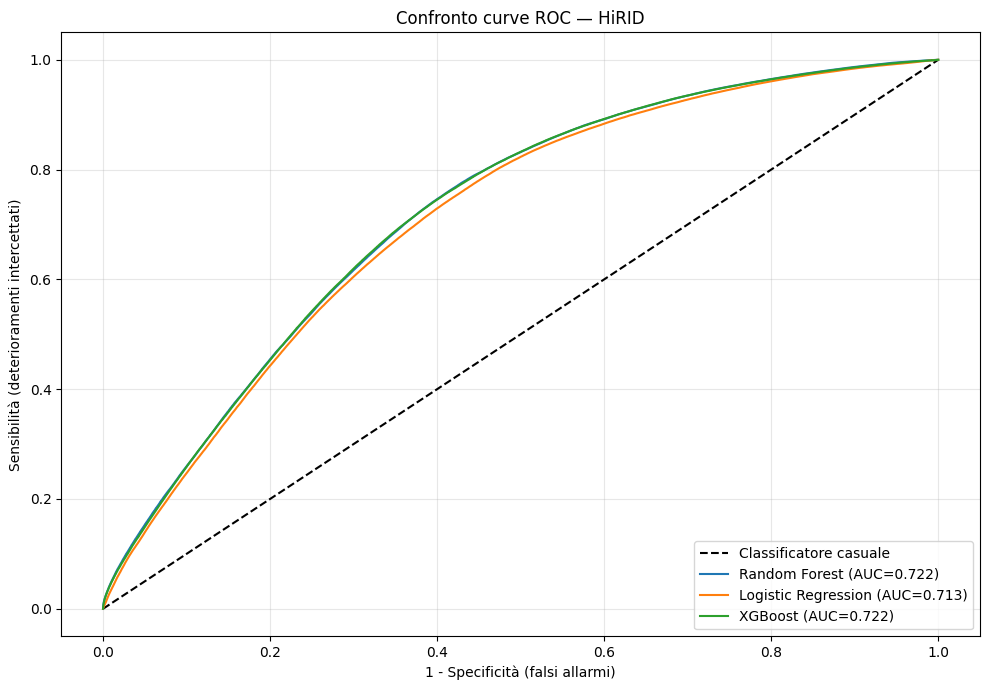

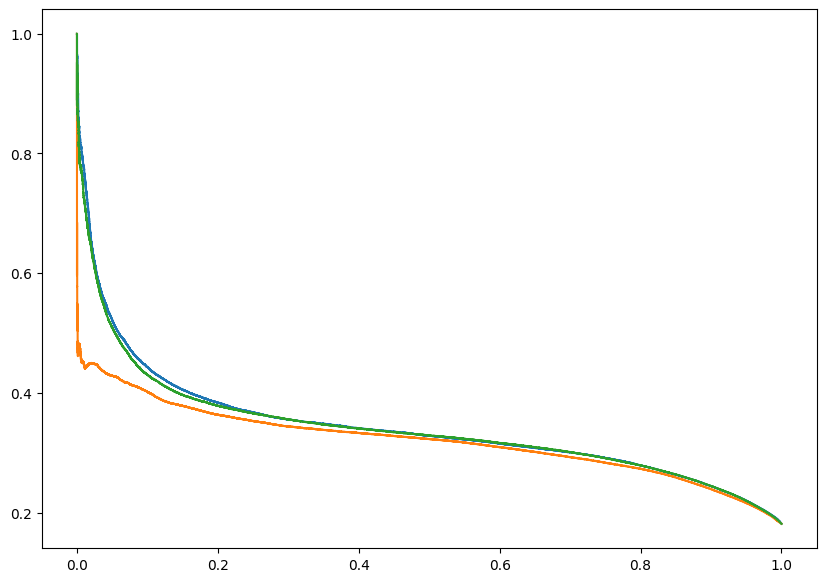

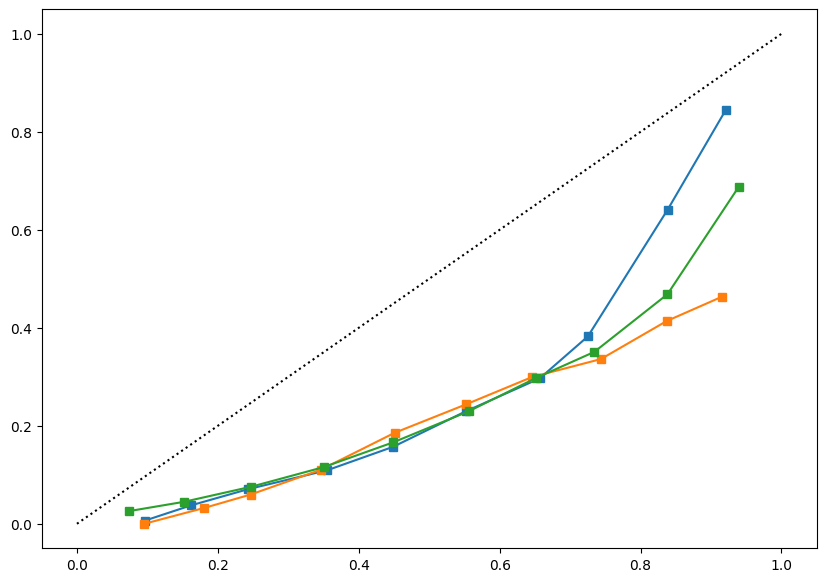


✓ Grafici e Modelli salvati in outputs/


In [33]:
# =============================================================================
# ADDESTRAMENTO E CALIBRAZIONE MODELLI
# =============================================================================
from sklearn.metrics import precision_recall_curve, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
import os
import matplotlib.pyplot as plt
import numpy as np

risultati = {}
os.makedirs("outputs", exist_ok=True)

fig_roc, ax_roc = plt.subplots(figsize=(10, 7))
ax_roc.plot([0,1], [0,1], 'k--', label='Classificatore casuale')

fig_pr, ax_pr = plt.subplots(figsize=(10, 7))

fig_cal, ax_cal = plt.subplots(figsize=(10, 7))
ax_cal.plot([0, 1], [0, 1], "k:", label="Perfettamente calibrato")

for nome, modello in modelli.items():
    print(f"\nAddestrando {nome}...")

    try:   # training non bloccante: se un modello fallisce, logghiamo e passiamo al successivo
        if nome == 'Logistic Regression':
            modello.fit(X_train_scaled, y_train)
            prob_val  = modello.predict_proba(X_val_scaled)[:, 1]
            prob_test = modello.predict_proba(X_test_scaled)[:, 1]
        else:
            modello.fit(X_train, y_train)
            prob_val  = modello.predict_proba(X_val)[:, 1]
            prob_test = modello.predict_proba(X_test)[:, 1]
    except Exception as e:
        logger.error(f"Training fallito per '{nome}', modello escluso dal confronto: {e}")
        continue

    # Soglia ottimale con Youden sul validation set
    fpr_val, tpr_val, soglie_val = roc_curve(y_val, prob_val)
    youden = tpr_val - fpr_val
    soglia_ottimale = soglie_val[np.argmax(youden)]
    print(f"  Soglia ottimale (Youden): {soglia_ottimale:.3f}")

    # Metriche sul VALIDATION: servono solo a scegliere il modello (il test resta per la valutazione finale)
    auc_val   = roc_auc_score(y_val, prob_val)
    ap_val    = average_precision_score(y_val, prob_val)
    brier_val = brier_score_loss(y_val, prob_val)

    # Predizioni sul test set
    y_pred = (prob_test >= soglia_ottimale).astype(int)

    # Calcolo metriche standard
    auc  = roc_auc_score(y_test, prob_test)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    ap   = average_precision_score(y_test, prob_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificita = tn / (tn + fp)

    # Calcolo metrica di calibrazione (Brier Score - più basso è meglio)
    brier = brier_score_loss(y_test, prob_test)

    risultati[nome] = {
        'AUC':         round(auc, 3),
        'F1':          round(f1, 3),
        'Sensibilità': round(rec, 3),
        'Specificità': round(specificita, 3),
        'Precisione':  round(prec, 3),
        'AP':          round(ap, 3),
        'Soglia':      round(soglia_ottimale, 3),
        'Brier Score': round(brier, 3),
        'AUC_val':   round(auc_val, 3),
        'AP_val':    round(ap_val, 3),
        'Brier_val': round(brier_val, 3),
    }

    print(f"  AUC={auc:.3f} | F1={f1:.3f} | Sensibilità={rec:.3f} | Brier={brier:.3f}")

    # Curve per i grafici
    fpr_test, tpr_test, _ = roc_curve(y_test, prob_test)
    ax_roc.plot(fpr_test, tpr_test, label=f"{nome} (AUC={auc:.3f})")

    precision_vals, recall_vals, _ = precision_recall_curve(y_test, prob_test)
    ax_pr.plot(recall_vals, precision_vals, label=f"{nome} (AP={ap:.3f})")

    prob_true, prob_pred = calibration_curve(y_test, prob_test, n_bins=10)
    ax_cal.plot(prob_pred, prob_true, marker='s', label=f"{nome} (Brier={brier:.3f})")

if not risultati:   # tutti e tre i modelli hanno fallito: fermiamoci qui, non ha senso proseguire con grafici vuoti
    raise ErroreModello("Nessun modello addestrato con successo su HiRID: controlla logs/pipeline_tesi.log")

# Salvataggio Curve ROC
ax_roc.set_xlabel('1 - Specificità (falsi allarmi)')
ax_roc.set_ylabel('Sensibilità (deterioramenti intercettati)')
ax_roc.set_title('Confronto curve ROC — HiRID')
ax_roc.legend(loc='lower right')
ax_roc.grid(alpha=0.3)
fig_roc.tight_layout()
fig_roc.savefig("outputs/confronto_roc_hirid.png", dpi=150)
plt.show()
plt.close(fig_roc)

# Salvataggio Curve Precision-Recall
baseline_pr = (y_test == 1).sum() / len(y_test)
ax_pr.axhline(y=baseline_pr, color='k', linestyle='--', label=f'Classificatore casuale (AP={baseline_pr:.3f})')
ax_pr.set_xlabel('Recall (Sensibilità)')
ax_pr.set_ylabel('Precisione')
ax_pr.set_title('Confronto curve Precision-Recall — HiRID')
ax_pr.legend(loc='upper right')
ax_pr.grid(alpha=0.3)
fig_pr.tight_layout()
fig_pr.savefig("outputs/confronto_pr_hirid.png", dpi=150)
plt.show()
plt.close(fig_pr)

# Salvataggio Curva di Calibrazione
ax_cal.set_xlabel("Probabilità Predetta Media")
ax_cal.set_ylabel("Frazione di Positivi Reali")
ax_cal.set_title("Curve di Calibrazione (Affidabilità Clinica) — HiRID")
ax_cal.legend(loc="lower right")
ax_cal.grid(alpha=0.3)
fig_cal.tight_layout()
fig_cal.savefig("outputs/confronto_calibrazione_hirid.png", dpi=150)
plt.show()
plt.close(fig_cal)

print("\n✓ Grafici e Modelli salvati in outputs/")

### Scelta del modello migliore
Il modello si sceglie sulla **validazione**, mai sul test, con un punteggio composito:

**40% AUC + 30% AUPRC + 30% (1 − Brier)**

- AUC e AUPRC misurano quanto il modello distingue i pazienti a rischio da quelli stabili (l'AUPRC è più informativa con classi sbilanciate);
- il Brier misura quanto sono affidabili le probabilità, qui ancora **grezze** (prima della ricalibrazione).

Le metriche sul test compaiono nella tabella per completezza, ma non entrano nella scelta.

**Verifica (28/09/2026):** ricalibrando prima tutti e tre i modelli, oppure togliendo il Brier dal punteggio,
su HiRID vince comunque Random Forest. La ricalibrazione fatta dopo non ha influito sulla scelta
(notebook `verifica_ricalibrazione_hirid.ipynb`).

In [34]:
# =============================================================================
# TABELLA RIASSUNTIVA E SCELTA MODELLO MIGLIORE
# =============================================================================
# Criterio allineato a quello usato in MIMIC-IV/eICU-CRD: non la sola AUC, ma un
# punteggio composito che pesa anche AUPRC (piu' informativo con classi sbilanciate)
# e calibrazione (Brier Score) - due modelli con AUC quasi identica (qui RF e
# XGBoost differiscono di appena 0.001) possono comportarsi diversamente su
# questi altri due aspetti, rilevanti clinicamente quanto la sola discriminazione.

df_risultati = pd.DataFrame(risultati).T

# Punteggio composito calcolato sul VALIDATION: il test resta solo per la valutazione finale
df_risultati['punteggio_composito'] = (
    0.40 * df_risultati['AUC_val'] +
    0.30 * df_risultati['AP_val'] +
    0.30 * (1 - df_risultati['Brier_val'])
)
df_risultati = df_risultati.sort_values('punteggio_composito', ascending=False)

print()
print("="*70)
print("CONFRONTO MODELLI - HiRID")
print("="*70)
print("Criteri di selezione:")
print("  40% - AUC          (discriminazione)")
print("  30% - AP (AUPRC)   (performance su classi sbilanciate)")
print("  30% - 1-Brier      (calibrazione - affidabilita' clinica)")
print("="*70)
print(df_risultati.to_string())

# Modello migliore per punteggio composito (non piu' la sola AUC)
migliore = df_risultati.index[0]
print()
print(f"OK - Modello migliore per punteggio composito: {migliore}")
print(f"  AUC={df_risultati.loc[migliore,'AUC']} | "
      f"AP={df_risultati.loc[migliore,'AP']} | "
      f"Brier={df_risultati.loc[migliore,'Brier Score']} | "
      f"Punteggio composito={df_risultati.loc[migliore,'punteggio_composito']:.4f}")

# Salva il modello migliore
import joblib
modello_migliore = modelli[migliore]
os.makedirs("models", exist_ok=True)
joblib.dump(modello_migliore, "models/modello_news2_hirid.pkl")
print()
print("OK - Modello salvato in models/modello_news2_hirid.pkl")

print()
print("="*70)
print("FASE 2 COMPLETATA - HiRID")
print("="*70)



CONFRONTO MODELLI - HiRID
Criteri di selezione:
  40% - AUC          (discriminazione)
  30% - AP (AUPRC)   (performance su classi sbilanciate)
  30% - 1-Brier      (calibrazione - affidabilita' clinica)
                       AUC     F1  Sensibilità  Specificità  Precisione     AP  Soglia  Brier Score  AUC_val  AP_val  Brier_val  punteggio_composito
Random Forest        0.722  0.419        0.752        0.594       0.291  0.343   0.492        0.213    0.730   0.363      0.211               0.6376
XGBoost              0.722  0.419        0.748        0.598       0.291  0.340   0.487        0.211    0.729   0.359      0.210               0.6363
Logistic Regression  0.713  0.411        0.746        0.584       0.284  0.320   0.454        0.216    0.722   0.339      0.214               0.6263

OK - Modello migliore per punteggio composito: Random Forest
  AUC=0.722 | AP=0.343 | Brier=0.213 | Punteggio composito=0.6376

OK - Modello salvato in models/modello_news2_hirid.pkl

FASE 2 COMPLET

### Confronto con il NEWS-2 usato da solo
Il NEWS-2 è un punteggio: si usa direttamente per ordinare i pazienti (più è alto, più il rischio è alto),
senza addestrare nulla. Calcolando l'AUC sugli **stessi pazienti del test** si confronta il modello con ciò
che si usa già in clinica: è il primo obiettivo della tesi.

Per completezza si confrontano anche altri riferimenti semplici: la media e il massimo del NEWS-2 nelle
ultime 6 ore e il Delta-NEWS a 6 ore usato da solo.

In [35]:
# CONFRONTO CON IL NEWS-2 USATO DA SOLO
X_test_modello = X_test_scaled if migliore == "Logistic Regression" else X_test
prob_modello = modello_migliore.predict_proba(X_test_modello)[:, 1]

confronto = {
    "NEWS-2 istantaneo (pratica clinica)": X_test["news2"],
    "NEWS-2 media ultime 6h":              X_test["news2_media_6h"],
    "NEWS-2 massimo ultime 6h":            X_test["news2_max_6h"],
    "Delta-NEWS 6h da solo":               X_test["delta_news_6h"],
    f"Modello completo ({migliore})":      prob_modello,
}
print("=" * 60)
print("AUC sul test — HiRID")
print("=" * 60)
for nome, punteggio in confronto.items():
    print(f"  {nome:38s} {roc_auc_score(y_test, punteggio):.3f}")

AUC sul test — HiRID


  NEWS-2 istantaneo (pratica clinica)    0.688


  NEWS-2 media ultime 6h                 0.694


  NEWS-2 massimo ultime 6h               0.668


  Delta-NEWS 6h da solo                  0.537


  Modello completo (Random Forest)       0.722


### Explainable AI: interpretabilità clinica con SHAP

In ambito clinico, un modello di Machine Learning non può limitarsi a produrre una predizione senza spiegarla. Tramite il framework SHAP (*SHapley Additive exPlanations*), basato sulla teoria dei giochi, è possibile analizzare il contributo di ogni variabile alla singola predizione. Il *Summary Plot*, generato su un campione del test set, mostra quali parametri fisiologici spingono il punteggio verso l'alto o verso il basso — e di quanto. Questo permette di verificare che il modello abbia imparato associazioni coerenti con la fisiopatologia reale del deterioramento clinico, e non associazioni casuali legate al rumore nei dati.

Nota di lettura: nel lavoro il Delta-NEWS **non** è risultato tra le variabili più influenti (anche usato da solo
ha un'AUC vicina al caso), quindi non va presentato come il fattore principale del modello.

Usa `modello_migliore` (calcolato nella cella precedente): se risultasse la Logistic Regression, viene usato automaticamente il test set scalato, altrimenti quello originale — evita di passare dati con la scala sbagliata a un modello che non se l'aspetta.

Calcolo dei valori SHAP per l'interpretabilità clinica...


 21%|====                | 828/4000 [00:11<00:42]       

 23%|=====               | 906/4000 [00:12<00:40]       

 25%|=====               | 983/4000 [00:13<00:39]       

 27%|=====               | 1064/4000 [00:14<00:38]       

...

 95%|=================== | 3790/4000 [01:16<00:04]       

 95%|=================== | 3811/4000 [01:17<00:03]       

 96%|=================== | 3839/4000 [01:18<00:03]       

 98%|===================| 3907/4000 [01:19<00:01]       

100%|===================| 3981/4000 [01:20<00:00]       

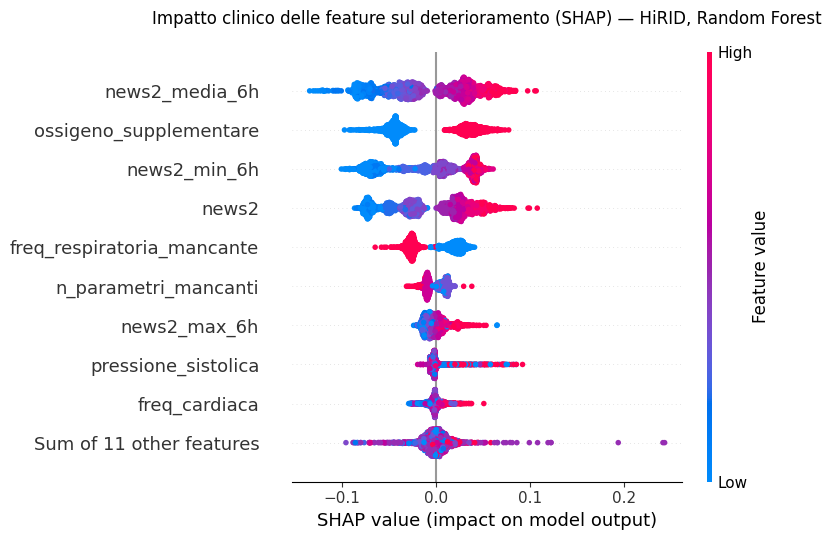

In [36]:
# =============================================================================
# EXPLAINABLE AI: Interpretabilità del Modello con SHAP
# =============================================================================
import shap
import matplotlib.pyplot as plt

print("Calcolo dei valori SHAP per l'interpretabilità clinica...")

# Il test set nella scala giusta per il modello migliore: scalato per la Logistic
# Regression, originale per Random Forest/XGBoost (che non usano lo scaler).
X_test_per_shap = X_test_scaled if migliore == 'Logistic Regression' else X_test

esploratore = shap.Explainer(modello_migliore, X_train_scaled if migliore == 'Logistic Regression' else X_train)

n_campione = min(2000, len(X_test_per_shap))   # min(): il test set HiRID potrebbe essere più piccolo di 2000 righe
X_campione = X_test_per_shap.sample(n_campione, random_state=42)

valori_shap = esploratore(X_campione)

plt.figure(figsize=(10, 8))

# Per modelli a due classi (RF/XGBoost) i valori SHAP hanno una terza dimensione
# per la classe; per la Logistic Regression no. Gestiamo entrambi i casi.
valori_da_plottare = valori_shap[:, :, 1] if valori_shap.values.ndim == 3 else valori_shap
shap.plots.beeswarm(valori_da_plottare, max_display=10, show=False)

plt.title(f"Impatto clinico delle feature sul deterioramento (SHAP) — HiRID, {migliore}", pad=20)
plt.tight_layout()

plt.savefig('outputs/shap_beeswarm_hirid.png', dpi=150)
plt.show()

### Intervallo di confidenza al 95% — bootstrap per paziente
Il test è un gruppo di pazienti scelto a caso: con un altro gruppo simile l'AUC sarebbe un po' diversa.
L'intervallo di confidenza al 95% dice **di quanto**, cioè quanto è stabile il risultato.

Si calcola **alla fine, solo sul modello già scelto** e solo sui pazienti del test: non serve a scegliere il
modello (la scelta è già stata fatta sulla validazione).

**Procedimento (bootstrap):**
1. dai pazienti del test se ne estrae a caso lo stesso numero, **con reinserimento** (lo stesso paziente può uscire più volte, un altro nessuna);
2. si ricalcola l'AUC su questo nuovo gruppo;
3. si ripete 1.000 volte: l'intervallo al 95% va dal 2,5° al 97,5° percentile delle 1.000 AUC.

Non si aggiungono pazienti nuovi, non si modificano i dati e non si riaddestra il modello: cambia solo quali
pazienti contano.

**Ricampionamento per paziente.** Il test set contiene molte righe per ogni paziente (una ogni 10 minuti), fortemente correlate tra loro. Il bootstrap quindi ricampiona i **pazienti** (con reinserimento) e per ciascuno tiene tutte le sue righe: è il cosiddetto *cluster bootstrap*. Ricampionare le singole righe tratterebbe come indipendenti misure che non lo sono e produrrebbe intervalli di confidenza artificialmente stretti (circa ±0,001 invece di circa ±0,01).

**Come si legge:** un intervallo stretto vuol dire che il risultato non dipende da quali pazienti sono capitati
nel test. Se gli intervalli di due database si sovrappongono quasi del tutto, la differenza tra le due AUC non
va considerata reale. L'intervallo non dice se il modello funziona in altri ospedali: questo lo mostra il
confronto tra i tre database.

In [37]:
# =============================================================================
# STATISTICA AVANZATA: Intervalli di Confidenza (95% CI) per l'AUC
# =============================================================================
import numpy as np
from sklearn.utils import resample
from sklearn.metrics import roc_auc_score

print("Calcolo degli Intervalli di Confidenza al 95% tramite Bootstrapping...")
print("(Questa operazione richiederà circa 10-20 secondi)\n")

# Stessa logica della cella SHAP: usa il test set scalato se il modello migliore
# è la Logistic Regression, altrimenti quello originale.
X_test_per_bootstrap = X_test_scaled if migliore == 'Logistic Regression' else X_test
prob_test_migliore = modello_migliore.predict_proba(X_test_per_bootstrap)[:, 1]

n_bootstraps = 1000
rng_seed = 42
# Bootstrap PER PAZIENTE (cluster bootstrap): si ricampionano i pazienti del test set con
# reinserimento e si tengono tutte le loro righe. Le righe dello stesso paziente sono molto simili
# tra loro (una ogni 10 minuti): ricampionare le singole righe, come si faceva prima, trattava come
# indipendenti misure che non lo sono e dava intervalli falsamente stretti (circa +-0,001).
# Un paziente estratto k volte pesa k volte: lo si ottiene con sample_weight, senza copiare le righe.
id_test = np.asarray(df_test["patientid"])                             # patientid di ogni riga del test set
codici_paz, pazienti_test = pd.factorize(id_test)           # ogni patientid -> un numero 0..N-1
n_paz = len(pazienti_test)
y_boot = np.asarray(y_test)
rng_boot = np.random.default_rng(42)

punteggi_auc_bootstrap = []
for i in range(1000):
    estratti = rng_boot.integers(0, n_paz, n_paz)                 # N pazienti estratti con reinserimento
    peso = np.bincount(estratti, minlength=n_paz)[codici_paz]      # quante volte e' stato estratto il paziente di ogni riga
    tenute = peso > 0
    if len(np.unique(y_boot[tenute])) < 2:
        continue
    punteggi_auc_bootstrap.append(
        roc_auc_score(y_boot[tenute], prob_test_migliore[tenute], sample_weight=peso[tenute]))

limite_inferiore = np.percentile(punteggi_auc_bootstrap, 2.5)
limite_superiore = np.percentile(punteggi_auc_bootstrap, 97.5)
auc_originale = roc_auc_score(y_boot, prob_test_migliore)

print("="*60)
print(f"RISULTATI STATISTICI - {migliore} (Test Set) — HiRID")
print("="*60)
print(f"Pazienti nel test set: {n_paz:,} | righe: {len(y_boot):,}")
print(f"AUC puntuale: {auc_originale:.3f}")
print(f"95% CI (bootstrap per paziente, 1000 iterazioni): [{limite_inferiore:.3f} - {limite_superiore:.3f}]")
print("="*60)


Calcolo degli Intervalli di Confidenza al 95% tramite Bootstrapping...
(Questa operazione richiederà circa 10-20 secondi)



RISULTATI STATISTICI - Random Forest (Test Set) — HiRID
Pazienti nel test set: 6,780 | righe: 2,176,671
AUC puntuale: 0.722
95% CI (bootstrap per paziente, 1000 iterazioni): [0.711 - 0.733]


### Ricalibrazione delle probabilità (isotonic regression)
Le curve di calibrazione mostrano che il modello **sovrastima** il rischio: la probabilità predetta è più alta
della frequenza osservata su quasi tutto l'intervallo (Brier peggiore del Brier banale della sola prevalenza).
È l'effetto atteso di `class_weight='balanced'` / `scale_pos_weight`: in addestramento i casi di
deterioramento, che sono pochi, pesano di più, e il modello impara come se fossero circa la metà.

Correggiamo con una **regressione isotonica**: una trasformazione monotona appresa SOLO sul validation set
(mai sul test, per non introdurre data leakage) che mappa la probabilità grezza del modello nella probabilità
calibrata. L'AUC non cambia per costruzione (la trasformazione è monotona, non altera l'ordinamento dei
pazienti per rischio): cambia solo l'affidabilità del numero, utile per un'eventuale soglia clinica basata sul
rischio assoluto e non solo sul ranking.

La ricalibrazione si applica **dopo** la scelta del modello e solo al modello scelto. È stato verificato che,
ricalibrando prima tutti e tre i modelli, la scelta non cambia.

RICALIBRAZIONE (isotonic, adattata sul validation) — Random Forest
Brier PRIMA della ricalibrazione : 0.2128
Brier DOPO  la ricalibrazione    : 0.1346
AUC   PRIMA della ricalibrazione : 0.7223
AUC   DOPO  la ricalibrazione    : 0.7221  (invariata per costruzione, a meno di pareggi)


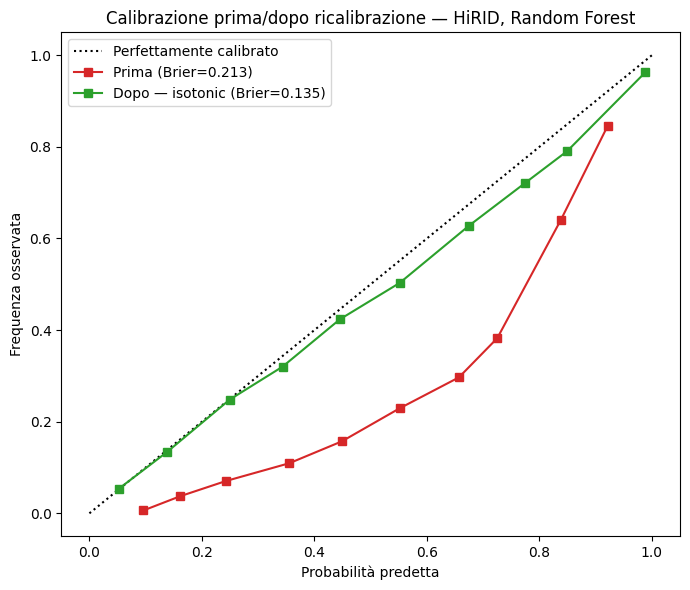


OK - Regressione isotonica salvata in models/isotonic_hirid.pkl
Per una probabilita' calibrata: calibratore.predict(modello.predict_proba(X)[:, 1])


In [38]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

X_val_per_cal  = X_val_scaled  if migliore == 'Logistic Regression' else X_val
X_test_per_cal = X_test_scaled if migliore == 'Logistic Regression' else X_test

prob_val_migliore   = modello_migliore.predict_proba(X_val_per_cal)[:, 1]
prob_test_migliore2 = modello_migliore.predict_proba(X_test_per_cal)[:, 1]   # ricalcolata qui per chiarezza, stessa di prob_test_migliore sopra

calibratore = IsotonicRegression(out_of_bounds="clip")
calibratore.fit(prob_val_migliore, y_val)   # la mappa si impara SOLO sul validation, mai sul test

prob_test_calibrata = calibratore.predict(prob_test_migliore2)

brier_prima = brier_score_loss(y_test, prob_test_migliore2)
brier_dopo  = brier_score_loss(y_test, prob_test_calibrata)
auc_prima   = roc_auc_score(y_test, prob_test_migliore2)
auc_dopo    = roc_auc_score(y_test, prob_test_calibrata)

print("=" * 60)
print(f"RICALIBRAZIONE (isotonic, adattata sul validation) — {migliore}")
print("=" * 60)
print(f"Brier PRIMA della ricalibrazione : {brier_prima:.4f}")
print(f"Brier DOPO  la ricalibrazione    : {brier_dopo:.4f}")
print(f"AUC   PRIMA della ricalibrazione : {auc_prima:.4f}")
print(f"AUC   DOPO  la ricalibrazione    : {auc_dopo:.4f}  (invariata per costruzione, a meno di pareggi)")
print("=" * 60)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k:", label="Perfettamente calibrato")
pt0, pp0 = calibration_curve(y_test, prob_test_migliore2, n_bins=10)
pt1, pp1 = calibration_curve(y_test, prob_test_calibrata, n_bins=10)
ax.plot(pp0, pt0, "s-", color="tab:red", label=f"Prima (Brier={brier_prima:.3f})")
ax.plot(pp1, pt1, "s-", color="tab:green", label=f"Dopo — isotonic (Brier={brier_dopo:.3f})")
ax.set_xlabel("Probabilità predetta"); ax.set_ylabel("Frequenza osservata")
ax.set_title(f"Calibrazione prima/dopo ricalibrazione — HiRID, {migliore}")
ax.legend(); plt.tight_layout()
plt.savefig("outputs/calibrazione_isotonic_hirid.png", dpi=150)
plt.show()

joblib.dump(calibratore, "models/isotonic_hirid.pkl")
print()
print("OK - Regressione isotonica salvata in models/isotonic_hirid.pkl")
print("Per una probabilita' calibrata: calibratore.predict(modello.predict_proba(X)[:, 1])")


### Decision Curve Analysis sulle probabilità calibrate
La DCA confronta il **beneficio netto** del modello con due strategie banali: dare l'allarme a tutti o a nessuno
(Vickers & Elkin, *Medical Decision Making*, 2006). Nella DCA la soglia è un rischio assoluto
("intervengo sopra il 20%"), quindi servono probabilità calibrate: si usa il modello scelto dopo la
ricalibrazione isotonica.

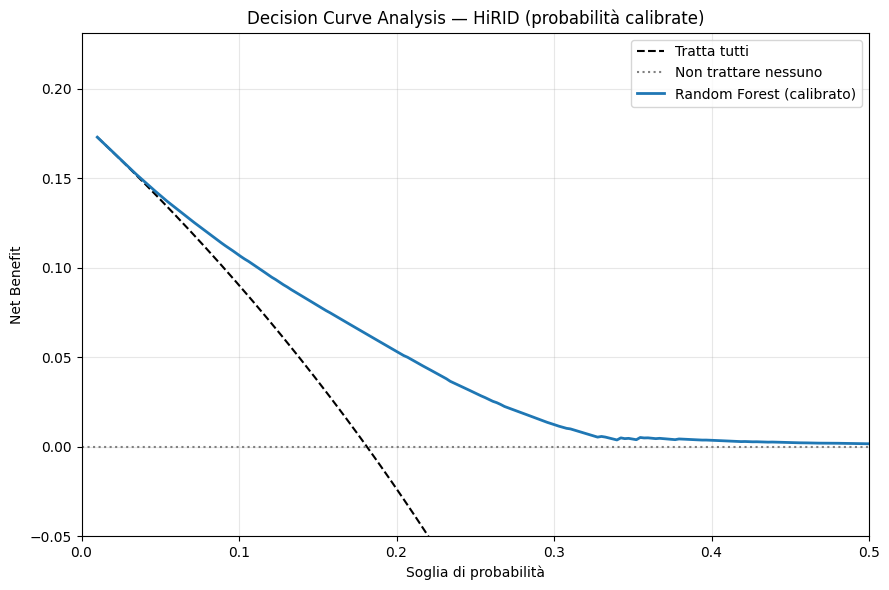

  DCA salvata in outputs/decision_curve_analysis_hirid.png


In [39]:
# =============================================================================
# DECISION CURVE ANALYSIS SULLE PROBABILITÀ CALIBRATE 
# =============================================================================
def decision_curve_analysis(y_true, prob_dict, thresholds=None, title="Decision Curve Analysis"):
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.50, 200)
    n = len(y_true)
    prevalenza = y_true.mean()
    fig, ax = plt.subplots(figsize=(9, 6))
    nb_tutti = [prevalenza - (1 - prevalenza) * (t / (1 - t)) for t in thresholds]
    ax.plot(thresholds, nb_tutti, "k--", label="Tratta tutti", linewidth=1.5)
    ax.axhline(0, color="gray", linestyle=":", label="Non trattare nessuno", linewidth=1.5)
    for nome, prob in prob_dict.items():
        nb_model = []
        for t in thresholds:
            y_pred = (prob >= t).astype(int)
            tp = ((y_pred == 1) & (y_true == 1)).sum()
            fp = ((y_pred == 1) & (y_true == 0)).sum()
            nb_model.append(tp / n - fp / n * (t / (1 - t)))
        ax.plot(thresholds, nb_model, label=nome, linewidth=2)
    ax.set_xlabel("Soglia di probabilità"); ax.set_ylabel("Net Benefit")
    ax.set_title(title); ax.set_xlim(0, 0.5); ax.set_ylim(-0.05, prevalenza + 0.05)
    ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
    fig.savefig("outputs/decision_curve_analysis_hirid.png", dpi=150)
    plt.show(); plt.close(fig)
    print("  DCA salvata in outputs/decision_curve_analysis_hirid.png")

decision_curve_analysis(
    y_test.values,
    {f"{migliore} (calibrato)": prob_test_calibrata},
    title="Decision Curve Analysis — HiRID (probabilità calibrate)"
)

### Tempo di anticipo degli allarmi
L'AUC valuta ogni blocco di 10 minuti. Un medico però chiede: **quanto prima mi avvisa il sistema, per ogni evento?**
Per ogni evento dei pazienti del test (morte, inizio di un vasopressore, intubazione) si guardano le **24 ore precedenti**,
la stessa finestra dell'etichetta:
- l'evento è **intercettato** se in quelle 24 ore il modello supera almeno una volta la soglia di allarme (Youden, scelta sulla validazione);
- l'**anticipo** è il tempo tra il **primo** allarme della finestra e l'evento (massimo 24 ore);
- gli eventi senza nessuna osservazione nelle 24 ore precedenti (per esempio all'inizio del ricovero) non sono valutabili e sono contati a parte.

Si usa il modello già scelto, sulle probabilità grezze e con la stessa soglia: nessun nuovo addestramento, nessun risultato precedente cambia.
La misura "eventi segnalati con almeno 2 ore di anticipo" è confrontabile con Hyland et al., Nature Medicine 2020.

Per leggere correttamente questi numeri servono due confronti, calcolati nella stessa cella:
- **falsi allarmi**: nei ricoveri senza nessun evento, quanti ricevono comunque almeno un allarme e per quanta parte del tempo;
- **NEWS-2 come riferimento**: la stessa misura con le soglie cliniche del NEWS-2 (5 = risposta urgente, 7 = emergenza).


In [40]:
# =============================================================================
# TEMPO DI ANTICIPO DEGLI ALLARMI (analisi aggiunta, non cambia i risultati precedenti)
# =============================================================================
from sklearn.metrics import roc_curve

def tempo_di_anticipo(righe, eventi, chiavi, soglia, finestra_ore=24):
    # righe: chiavi + "t" (ore) + "prob"; eventi: chiavi + "t_evento" (ore) + "tipo_evento"
    eventi = eventi.drop_duplicates(chiavi + ["t_evento", "tipo_evento"]).reset_index(drop=True)
    eventi["id_evento"] = eventi.index
    m = eventi.merge(righe, on=chiavi, how="inner")
    m = m[(m["t"] < m["t_evento"]) & (m["t"] >= m["t_evento"] - finestra_ore)]   # solo le 24 ore PRIMA dell'evento
    per_evento = m.groupby("id_evento").agg(tipo=("tipo_evento", "first"), t_evento=("t_evento", "first"))
    per_evento["t_primo_allarme"] = m[m["prob"] >= soglia].groupby("id_evento")["t"].min()
    per_evento["anticipo_ore"] = per_evento["t_evento"] - per_evento["t_primo_allarme"]   # NaN = nessun allarme = evento mancato
    return per_evento, len(eventi)

def riassunto_anticipo(per_evento, n_eventi, nome_db):
    intercettato = per_evento["anticipo_ore"].notna()
    almeno_2h = per_evento["anticipo_ore"] >= 2
    anticipi = per_evento.loc[intercettato, "anticipo_ore"]
    print("=" * 70)
    print(f"TEMPO DI ANTICIPO DEGLI ALLARMI — {nome_db}")
    print("=" * 70)
    print(f"Eventi nei pazienti del test:                        {n_eventi:,}")
    print(f"Valutabili (almeno un'osservazione nelle 24 h prima): {len(per_evento):,}")
    print(f"Intercettati (almeno un allarme nelle 24 h prima):    {int(intercettato.sum()):,} ({100 * intercettato.mean():.1f}%)")
    print(f"Segnalati con almeno 2 ore di anticipo:               {int(almeno_2h.sum()):,} ({100 * almeno_2h.mean():.1f}%)")
    print(f"Anticipo del primo allarme (eventi intercettati): mediana {anticipi.median():.1f} ore, "
          f"IQR {anticipi.quantile(0.25):.1f}-{anticipi.quantile(0.75):.1f} ore")
    per_tipo = (per_evento.assign(intercettato=intercettato, almeno_2h=almeno_2h)
                .groupby("tipo")
                .agg(eventi=("intercettato", "size"),
                     intercettati_pct=("intercettato", "mean"),
                     almeno_2h_pct=("almeno_2h", "mean"),
                     anticipo_mediano_ore=("anticipo_ore", "median")))
    per_tipo[["intercettati_pct", "almeno_2h_pct"]] = (100 * per_tipo[["intercettati_pct", "almeno_2h_pct"]]).round(1)
    per_tipo["anticipo_mediano_ore"] = per_tipo["anticipo_mediano_ore"].round(1)
    print()
    print("Per tipo di evento:")
    print(per_tipo.to_string())
    print("=" * 70)

def carico_allarmi(righe, eventi, chiavi, soglia, nome):
    # Falsi allarmi: nei ricoveri SENZA nessun evento, quanto spesso il sistema dà comunque l'allarme?
    con_eventi = eventi[chiavi].drop_duplicates()
    senza = righe.merge(con_eventi.assign(_ev=1), on=chiavi, how="left")
    senza = senza[senza["_ev"].isna()]
    in_allarme = senza["prob"] >= soglia
    ricoveri_con_allarme = in_allarme.groupby([senza[k] for k in chiavi]).any()
    print(f"  {nome}: ricoveri senza eventi {ricoveri_con_allarme.size:,}; "
          f"con almeno un allarme {100 * ricoveri_con_allarme.mean():.1f}%; "
          f"tempo in allarme {100 * in_allarme.mean():.1f}% dei blocchi")

def confronto_con_news2(righe, eventi, chiavi, soglia_modello):
    # Stessa misura con il modello e con le soglie cliniche del NEWS-2 (5 = risposta urgente, 7 = emergenza)
    print()
    print("CONFRONTO CON IL NEWS-2 (stessi eventi, stessa finestra di 24 ore)")
    righe_news = righe.assign(prob=righe["news2"])
    riga = []
    for nome, r, s in [("Modello", righe, soglia_modello), ("NEWS-2 >= 5", righe_news, 5), ("NEWS-2 >= 7", righe_news, 7)]:
        pe, _ = tempo_di_anticipo(r[chiavi + ["t", "prob"]], eventi, chiavi, s)
        intercettato = pe["anticipo_ore"].notna()
        riga.append({"allarme": nome,
                     "intercettati_%": round(100 * intercettato.mean(), 1),
                     "almeno_2h_%": round(100 * (pe["anticipo_ore"] >= 2).mean(), 1),
                     "anticipo_mediano_ore": round(pe.loc[intercettato, "anticipo_ore"].median(), 1)})
    print(pd.DataFrame(riga).to_string(index=False))
    print()
    print("FALSI ALLARMI (ricoveri del test senza nessun evento)")
    carico_allarmi(righe, eventi, chiavi, soglia_modello, "Modello    ")
    carico_allarmi(righe_news, eventi, chiavi, 5, "NEWS-2 >= 5")
    carico_allarmi(righe_news, eventi, chiavi, 7, "NEWS-2 >= 7")

def ore(tempi):
    # istanti di tempo -> ore (numero), per poter fare differenze semplici
    return pd.to_datetime(tempi).astype("int64") / 3.6e12

# Soglia di allarme del modello migliore, ricalcolata sulla validazione come nel ciclo di addestramento
fpr_v, tpr_v, soglie_v = roc_curve(y_val, prob_val_migliore)
soglia_allarme = soglie_v[np.argmax(tpr_v - fpr_v)]
print(f"Soglia di allarme ({migliore}): {soglia_allarme:.3f}")

# Orari delle righe del test: stesso ordine del CSV di test (le righe di df dei pazienti di test)
righe_test = df.loc[df["patientid"].isin(test_ids), ["patientid", "datetime"]].reset_index(drop=True)
assert (righe_test["patientid"].values == df_test["patientid"].values).all(), "ordine delle righe diverso dal test"
righe_test["t"] = ore(righe_test["datetime"])
righe_test["prob"] = prob_test_migliore2
righe_test["news2"] = X_test["news2"].values

eventi_test = tutti_eventi.dropna(subset=["evento_time"])
eventi_test = eventi_test[eventi_test["patientid"].isin(test_ids)].copy()
eventi_test["patientid"] = eventi_test["patientid"].astype(righe_test["patientid"].dtype)
eventi_test["t_evento"] = ore(eventi_test["evento_time"])

per_evento, n_eventi = tempo_di_anticipo(righe_test[["patientid", "t", "prob"]],
                                         eventi_test[["patientid", "t_evento", "tipo_evento"]],
                                         ["patientid"], soglia_allarme)
riassunto_anticipo(per_evento, n_eventi, "HiRID")
print("Nota: in HiRID l'istante della morte è stimato con l'ultima misura, quindi l'anticipo sui decessi è approssimato.")
confronto_con_news2(righe_test, eventi_test[["patientid", "t_evento", "tipo_evento"]], ["patientid"], soglia_allarme)


Soglia di allarme (Random Forest): 0.492


TEMPO DI ANTICIPO DEGLI ALLARMI — HiRID
Eventi nei pazienti del test:                        7,903
Valutabili (almeno un'osservazione nelle 24 h prima): 7,542
Intercettati (almeno un allarme nelle 24 h prima):    7,193 (95.4%)
Segnalati con almeno 2 ore di anticipo:               3,971 (52.7%)
Anticipo del primo allarme (eventi intercettati): mediana 5.2 ore, IQR 0.3-23.9 ore

Per tipo di evento:
              eventi  intercettati_pct  almeno_2h_pct  anticipo_mediano_ore
tipo                                                                       
intubazione     4072              95.5           46.3                   1.5
morte            373             100.0           97.1                  24.0
vasopressore    3097              94.6           55.7                   6.5
Nota: in HiRID l'istante della morte è stimato con l'ultima misura, quindi l'anticipo sui decessi è approssimato.

CONFRONTO CON IL NEWS-2 (stessi eventi, stessa finestra di 24 ore)


    allarme  intercettati_%  almeno_2h_%  anticipo_mediano_ore
    Modello            95.4         52.7                   5.2
NEWS-2 >= 5            80.2         54.1                  14.7
NEWS-2 >= 7            63.5         49.1                  18.2

FALSI ALLARMI (ricoveri del test senza nessun evento)
  Modello    : ricoveri senza eventi 3,135; con almeno un allarme 68.0%; tempo in allarme 12.9% dei blocchi
  NEWS-2 >= 5: ricoveri senza eventi 3,135; con almeno un allarme 84.9%; tempo in allarme 24.6% dei blocchi


  NEWS-2 >= 7: ricoveri senza eventi 3,135; con almeno un allarme 52.3%; tempo in allarme 8.8% dei blocchi


### Consensus dei tre modelli (ensemble)
Proposta del professore (30 settembre 2026): invece di scegliere un solo modello, si mettono insieme le risposte dei tre
(regressione logistica, Random Forest, XGBoost) per arrivare a una risposta sola. Nessun riaddestramento.
- Ogni modello viene prima ricalibrato (isotonica, sul validation): le tre probabilità finiscono sulla stessa scala
- **Media**: media semplice delle tre probabilità (soft voting)
- **Media pesata**: pesi scelti sul validation con lo stesso punteggio composito usato per scegliere il modello
- **Voto a maggioranza**: allarme se almeno 2 modelli su 3 superano la propria soglia di Youden
- Confronto sul test con il modello scelto, ricalibrato allo stesso modo; differenza di AUC con bootstrap per paziente appaiato

In [41]:
# =============================================================================
# CONSENSUS (ENSEMBLE) DEI TRE MODELLI — HiRID
# =============================================================================
# Invece di tenere un solo modello, si combinano le risposte dei tre gia' addestrati
# (nessun riaddestramento). Ogni modello viene prima ricalibrato con la regressione isotonica
# sul validation, cosi' le tre probabilita' sono sulla stessa scala; poi:
#   1) MEDIA       = media semplice delle tre probabilita' calibrate (soft voting)
#   2) MEDIA PESATA = pesi scelti sul validation con il punteggio composito (stesso criterio
#                    usato per scegliere il modello); il test resta cieco
#   3) VOTO        = numero di modelli in allarme (0-3), ciascuno con la sua soglia di Youden
#                    scelta sul validation; allarme del consensus = almeno 2 su 3 (maggioranza)
# Il confronto sul test e' con il modello scelto oggi; la differenza di AUC ha un intervallo
# di confidenza con bootstrap per paziente APPAIATO (stessi pazienti estratti per i due modelli).
import itertools
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, confusion_matrix

COLONNA_ID = "patientid"   # unita' del bootstrap: paziente (persona in eICU-CRD)

def _prob(nome, X, X_sc):
    return modelli[nome].predict_proba(X_sc if nome == "Logistic Regression" else X)[:, 1]

nomi = list(modelli.keys())
cal_val, cal_test, soglie = {}, {}, {}
for nome in nomi:
    pv, pt = _prob(nome, X_val, X_val_scaled), _prob(nome, X_test, X_test_scaled)
    iso = IsotonicRegression(out_of_bounds="clip").fit(pv, y_val)   # mappa imparata solo sul validation
    cal_val[nome], cal_test[nome] = iso.predict(pv), iso.predict(pt)
    fpr, tpr, thr = roc_curve(y_val, pv)
    soglie[nome] = (thr[np.argmax(tpr - fpr)], pv, pt)              # soglia di Youden sul validation (prob. grezze)

def _pesa(w, probs):   # somma pesata; clip per gli arrotondamenti (1.0000000000000002)
    return np.clip(sum(w_i * probs[n] for w_i, n in zip(w, nomi)), 0, 1)

def _composito(y, p):
    return 0.40 * roc_auc_score(y, p) + 0.30 * average_precision_score(y, p) + 0.30 * (1 - brier_score_loss(y, p))

# 1) Media semplice
media_val  = np.mean([cal_val[n] for n in nomi], axis=0)
media_test = np.mean([cal_test[n] for n in nomi], axis=0)

# 2) Media pesata: griglia di pesi a passi di 0,1 che sommano a 1, scelta sul validation
griglia = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(nomi)) if abs(sum(w) - 1) < 1e-9]
punteggi = [(_composito(y_val, _pesa(w, cal_val)), w) for w in griglia]
_, pesi = max(punteggi, key=lambda t: t[0])
pesata_test = _pesa(pesi, cal_test)

# 3) Voto: quanti modelli sono in allarme
voti_test = sum((soglie[n][2] >= soglie[n][0]).astype(int) for n in nomi)

# Modello scelto oggi, calibrato allo stesso modo (riferimento del confronto)
rif_test = cal_test[migliore]

def _riga(nome_riga, p, allarme=None):
    if allarme is None:   # soglia di Youden scelta sul validation per le probabilita' continue
        p_val = {"Modello scelto": cal_val[migliore], "Media": media_val,
                 "Media pesata": _pesa(pesi, cal_val)}[nome_riga.split(" (")[0]]
        fpr, tpr, thr = roc_curve(y_val, p_val)
        allarme = (p >= thr[np.argmax(tpr - fpr)]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, allarme).ravel()
    return {"AUC": roc_auc_score(y_test, p), "AUPRC": average_precision_score(y_test, p),
            "Brier": brier_score_loss(y_test, p) if p.max() <= 1 else np.nan,
            "Sensibilita": tp / (tp + fn), "Specificita": tn / (tn + fp)}

tabella = pd.DataFrame({
    f"Modello scelto ({migliore})": _riga("Modello scelto", rif_test),
    "Media": _riga("Media", media_test),
    "Media pesata": _riga("Media pesata", pesata_test),
    "Voto a maggioranza (>=2 su 3)": _riga("Voto", voti_test.astype(float), allarme=(voti_test >= 2).astype(int)),
}).T

# Bootstrap per paziente appaiato: differenza di AUC (consensus - modello scelto)
id_righe = np.asarray(df_test[COLONNA_ID])
codici, unici = pd.factorize(id_righe)
y_arr = np.asarray(y_test)
rng_c = np.random.default_rng(42)
diff_media, diff_pesata = [], []
for _ in range(1000):
    peso = np.bincount(rng_c.integers(0, len(unici), len(unici)), minlength=len(unici))[codici]
    k = peso > 0
    if len(np.unique(y_arr[k])) < 2:
        continue
    a_rif = roc_auc_score(y_arr[k], rif_test[k], sample_weight=peso[k])
    diff_media.append(roc_auc_score(y_arr[k], media_test[k], sample_weight=peso[k]) - a_rif)
    diff_pesata.append(roc_auc_score(y_arr[k], pesata_test[k], sample_weight=peso[k]) - a_rif)

print("=" * 78)
print("CONSENSUS DEI TRE MODELLI — HiRID (test set, probabilita' ricalibrate sul validation)")
print("=" * 78)
print("Pesi della media pesata (scelti sul validation): " + ", ".join(f"{n} {w:.1f}" for n, w in zip(nomi, pesi)))
print(tabella.round(3).to_string())
print("-" * 78)
for nome_d, d in [("Media", diff_media), ("Media pesata", diff_pesata)]:
    print(f"Differenza di AUC {nome_d} - modello scelto: {np.mean(d):+.4f}  "
          f"95% CI [{np.percentile(d, 2.5):+.4f} ; {np.percentile(d, 97.5):+.4f}]  (bootstrap per paziente, appaiato)")
print("Se l'intervallo contiene lo 0, il consensus non e' distinguibile dal modello scelto.")
tabella.to_csv("outputs/consensus_hirid.csv")
print("Tabella salvata in outputs/consensus_hirid.csv")


CONSENSUS DEI TRE MODELLI — HiRID (test set, probabilita' ricalibrate sul validation)
Pesi della media pesata (scelti sul validation): Random Forest 0.5, Logistic Regression 0.1, XGBoost 0.4
                                  AUC  AUPRC  Brier  Sensibilita  Specificita
Modello scelto (Random Forest)  0.722  0.339  0.135        0.752        0.594
Media                           0.723  0.343  0.134        0.758        0.590
Media pesata                    0.724  0.344  0.134        0.751        0.597
Voto a maggioranza (>=2 su 3)   0.686  0.274    NaN        0.754        0.593
------------------------------------------------------------------------------
Differenza di AUC Media - modello scelto: +0.0013  95% CI [+0.0006 ; +0.0020]  (bootstrap per paziente, appaiato)
Differenza di AUC Media pesata - modello scelto: +0.0023  95% CI [+0.0016 ; +0.0031]  (bootstrap per paziente, appaiato)
Se l'intervallo contiene lo 0, il consensus non e' distinguibile dal modello scelto.
Tabella salvata in o